# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:**

- **Устройство:** локально, Apple M3 Pro (18 ГБ общей памяти), PyTorch 2.15.0 на MPS; ultralytics 8.4.215, Python 3.12. Финальный прогон с `FAST_MODE = False` занял 3108 s (около 52 мин), из них RT-DETR (6.2) 1617 s.
- **Модель:** `yolo26n.pt`, sha256 `9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef`; для сравнения в 1.1 взят `yolo26s.pt`.
- **Датасет:** BCCD (Blood Cell Count and Detection), https://github.com/Shenggan/BCCD_Dataset, лицензия MIT. Сплиты из `ImageSets/Main` репозитория: train 205, val 87, test 72.
- **Бонусы:** 6.2, 6.3, 6.4, 6.5. Задачу 6.1 (доразметка) не делал: разметку 50+ картинок нужно делать руками.
- **Внешние источники:** документация ultralytics ([train settings](https://docs.ultralytics.com/modes/train/#train-settings), [YOLO26](https://docs.ultralytics.com/models/yolo26/), [RT-DETR](https://docs.ultralytics.com/models/rtdetr/), [экспорт](https://docs.ultralytics.com/modes/export/)). Код семинаров 5-6 не копировал; конвертация, эвристика и разбор ошибок написаны с нуля.
- **Замечания:** RT-DETR обучался с `batch=4` и `nbs=4`: при `batch=8` память MPS дошла до 15 ГБ, система ушла в своп, и ядро упало. Без `nbs=4` обучение не сходилось (подробности в 6.2). ONNX-экспорт использует `onnxslim` (0.1.99): его доустановил сам ultralytics при первом экспорте, в `requirements_cv.txt` его нет.

In [1]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.215, torch 2.15.0, device: mps


In [2]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}     # 6.1 (ручная доразметка) не делаю
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)


def sync_device():
    # на mps и cuda вычисления асинхронные: без синхронизации замер времени занижен
    if DEVICE == 'mps':
        torch.mps.synchronize()
    elif DEVICE == 0:
        torch.cuda.synchronize()


def measure_latency(model, device=DEVICE, imgsz=IMGSZ, n=20, warmup=5):
    # средняя задержка model.predict на одной картинке imgsz x imgsz в мс: предобработка + сеть + постобработка
    img = np.random.default_rng(SEED).integers(0, 256, (imgsz, imgsz, 3), dtype=np.uint8)
    times = []
    for i in range(warmup + n):
        start = time.perf_counter()
        model.predict(img, imgsz=imgsz, device=device, verbose=False)
        sync_device()
        if i >= warmup:
            times.append(time.perf_counter() - start)
    return 1000 * float(np.mean(times))


def count_params(model):
    return sum(p.numel() for p in model.model.parameters())


MODEL_INFO = dict(
    ultralytics=ultralytics.__version__,
    weights=weights_path.name,
    sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
    size_mb=round(weights_path.stat().st_size / 2**20, 2),
    params=count_params(model_coco),   # до первого predict: Conv и BN еще не слиты
    n_classes_coco=len(model_coco.names),
    latency_ms=round(measure_latency(model_coco), 2),
    latency_device=DEVICE_NAME,
    latency_imgsz=IMGSZ,
)

In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.215',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.29,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 11.49,
 'latency_device': 'mps',
 'latency_imgsz': 640}

In [6]:
# соседний размер для ответа 1.1: те же замеры для yolo26s на этом же устройстве
model_s = YOLO('yolo26s.pt')
params_s = count_params(model_s)
latency_s = measure_latency(model_s)
print(f"yolo26n: {MODEL_INFO['params']:,} параметров, {MODEL_INFO['latency_ms']:.1f} мс/картинка")
print(f"yolo26s: {params_s:,} параметров ({params_s / MODEL_INFO['params']:.1f}x), {latency_s:.1f} мс/картинка "
      f"({latency_s / MODEL_INFO['latency_ms']:.1f}x); {DEVICE_NAME}, {IMGSZ}x{IMGSZ}")
# на mps у маленьких сетей время съедают накладные расходы, поэтому сравниваем и на cpu (свежие объекты: predictor
# ultralytics запоминает устройство первого вызова)
latency_cpu = {w: measure_latency(YOLO(w), device='cpu') for w in (WEIGHTS, 'yolo26s.pt')}
print('cpu, мс/картинка:', {w: round(v, 1) for w, v in latency_cpu.items()},
      f"-> s медленнее в {latency_cpu['yolo26s.pt'] / latency_cpu[WEIGHTS]:.1f} раза")
del model_s

yolo26n: 2,572,280 параметров, 11.5 мс/картинка
yolo26s: 10,009,784 параметров (3.9x), 18.7 мс/картинка (1.6x); mps, 640x640
cpu, мс/картинка: {'yolo26n.pt': 44.1, 'yolo26s.pt': 77.5} -> s медленнее в 1.8 раза


**Ответ:** Беру `yolo26n`. У BCCD всего 205 train-картинок и 3 класса, поэтому емкости 2.6M параметров хватает: дообучение на 60 эпох шло 853 s (14.2 s/эпоха) на M3 Pro, на T4 должно уложиться в бюджет с запасом. Соседний `yolo26s` по таблице документации дает на COCO mAP50-95 48.6 против 40.9, но у него 9.5M параметров против 2.4M (у меня до слияния 10.0M против 2.6M, в 3.9 раза больше) и он медленнее: 2.5 против 1.7 мс на T4 TensorRT, 87 против 39 мс на CPU ONNX. В моих замерах s медленнее в 1.6 раза на MPS (18.7 против 11.5 мс) и в 1.8 раза на CPU (77.5 против 44.1 мс). На маленьком датасете прирост от s скорее съест переобучение, а время абляций выросло бы в 2-3 раза. Код и веса ultralytics распространяются под AGPL-3.0 (альтернатива - платная Enterprise-лицензия). AGPL требует открыть под той же лицензией исходный код всего проекта, который использует библиотеку или веса, если его распространяют или дают к нему доступ по сети. Для учебной работы это не мешает, для закрытого коммерческого продукта нужна Enterprise.

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [7]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect

    def count(block):
        return sum(p.numel() for p in block.parameters())

    return dict(backbone=count(layers[:n_backbone]), neck=count(layers[n_backbone:-1]), head=count(layers[-1:]))


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    feats = []
    hook = det_model.model[-1].register_forward_hook(lambda module, inputs, output: feats.extend(inputs[0]))
    det_model.eval()
    with torch.no_grad():
        out = det_model(torch.zeros(1, 3, imgsz, imgsz, device=next(det_model.parameters()).device))
    hook.remove()
    return [tuple(f.shape) for f in feats], out


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [8]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [9]:
y, branches = out
print('выход: y', shapes(y), '- 4 координаты бокса + 80 классов в каждой из 8400 точек')
for name, branch in branches.items():
    print(f'  {name}:', shapes(branch))
print('8400 =', ' + '.join(f'{s[-2]}*{s[-1]}' for s in feat_shapes), '=', sum(s[-2] * s[-1] for s in feat_shapes))

# слои по блокам: индекс, откуда вход, тип, параметры
n_backbone = len(arch.yaml['backbone'])
for i, layer in enumerate(arch.model):
    block = 'backbone' if i < n_backbone else ('head' if i == len(arch.model) - 1 else 'neck')
    print(f'{i:>2} {block:<8} from={str(layer.f):<12} {type(layer).__name__:<9} {sum(p.numel() for p in layer.parameters()):>9,}')
head = arch.model[-1]
print('параметры головы: one2many (cv2, cv3)', sum(p.numel() for m in (head.cv2, head.cv3) for p in m.parameters()),
      '| one2one', sum(p.numel() for m in (head.one2one_cv2, head.one2one_cv3) for p in m.parameters()))

выход: y (1, 84, 8400) - 4 координаты бокса + 80 классов в каждой из 8400 точек
  one2many: {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}
  one2one: {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}
8400 = 80*80 + 40*40 + 20*20 = 8400
 0 backbone from=-1           Conv            464
 1 backbone from=-1           Conv          4,672
 2 backbone from=-1           C3k2          6,640
 3 backbone from=-1           Conv         36,992
 4 backbone from=-1           C3k2         26,080
 5 backbone from=-1           Conv        147,712
 6 backbone from=-1           C3k2         87,040
 7 backbone from=-1           Conv        295,424
 8 backbone from=-1           C3k2        346,112
 9 backbone from=-1           SPPF        164,608
10 backbone from=-1           C2PSA       249,728
11 neck     from=-1           Upsample          0
12 neck     from=[-1, 6]      Conca

**Ответ:** Backbone (слои 0-10, 1.37M, 53% параметров) - сверточный экстрактор признаков: шаг за шагом уменьшает разрешение до 1/32 и повышает число каналов, в конце SPPF (пулинг по нескольким окнам) и C2PSA (self-attention). Neck (слои 11-22, 0.90M, 35%) - FPN+PAN: апсемплинг и Concat смешивают глубокие признаки (stride 32) с более ранними (stride 16 и 8), затем идет обратный проход вниз. На выходе три карты: 64x80x80, 128x40x40, 256x20x20. Head `Detect` (0.31M, 12%) в каждой точке каждой карты предсказывает 4 числа бокса (расстояния от точки до сторон, без DFL) и 80 скоров классов (без отдельной objectness), отсюда `y` формы 1x84x8400. Детектор anchor-free, потому что бокс регрессируется прямо от центра ячейки, а не как поправка к заранее заданным якорным рамкам. 8400 = 80^2 + 40^2 + 20^2 - число ячеек трех карт со stride 8, 16 и 32 при входе 640. Ветка `one2many` учится с назначением нескольких ячеек на один объект (больше сигнала, но дубли, нужен NMS). Ветка `one2one` (по 154 828 параметров у каждой) учится с назначением один к одному, поэтому дубли подавлены уже обучением и NMS не нужен - это и есть end-to-end режим YOLO26.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [10]:
import requests

BCCD_URL = 'https://github.com/Shenggan/BCCD_Dataset/archive/refs/heads/master.zip'
BCCD_DIR = DATA_ROOT / 'BCCD_Dataset-master' / 'BCCD'
CLASSES = ['RBC', 'WBC', 'Platelets']
DATASET_NAME = 'BCCD (Blood Cell Count and Detection), https://github.com/Shenggan/BCCD_Dataset, MIT License'

if not BCCD_DIR.exists():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    zip_path = DATA_ROOT / 'bccd.zip'
    resp = requests.get(BCCD_URL, timeout=300)   # requests берет сертификаты из certifi (urllib на macOS может не найти)
    resp.raise_for_status()
    zip_path.write_bytes(resp.content)
    shutil.unpack_archive(zip_path, DATA_ROOT)

FIXED_BOXES = []   # (файл, класс, исходный бокс, что сделали)


def parse_voc(xml_path):
    root = ET.parse(xml_path).getroot()
    w, h = int(root.find('size/width').text), int(root.find('size/height').text)
    boxes, labels = [], []
    for obj in root.iter('object'):
        name = obj.find('name').text.strip()
        bb = obj.find('bndbox')
        box = np.array([float(bb.find(k).text) for k in ('xmin', 'ymin', 'xmax', 'ymax')])
        clipped = np.clip(box, 0, [w, h, w, h])
        if clipped[2] <= clipped[0] or clipped[3] <= clipped[1]:
            FIXED_BOXES.append((xml_path.name, name, box.tolist(), 'zero_area: удален'))
            continue
        if (clipped != box).any():
            FIXED_BOXES.append((xml_path.name, name, box.tolist(), 'out_of_image: обрезан'))
        boxes.append(clipped)
        labels.append(CLASSES.index(name))   # неизвестное имя класса -> ValueError, а не тихий пропуск
    return dict(image=BCCD_DIR / 'JPEGImages' / f'{xml_path.stem}.jpg', width=w, height=h,
                boxes=np.array(boxes, dtype=np.float32).reshape(-1, 4), labels=np.array(labels, dtype=np.int64))


records = {split: [parse_voc(BCCD_DIR / 'Annotations' / f'{name}.xml')
                   for name in (BCCD_DIR / 'ImageSets' / 'Main' / f'{split}.txt').read_text().split()]
           for split in ('train', 'val', 'test')}   # официальные сплиты BCCD (ImageSets/Main)
print(DATASET_NAME)
fixed_kinds = Counter(f[3] for f in FIXED_BOXES)
print('исправленные боксы:', {k: fixed_kinds[k] for k in ('zero_area: удален', 'out_of_image: обрезан')})
for f in FIXED_BOXES:
    print('  ', *f)

BCCD (Blood Cell Count and Detection), https://github.com/Shenggan/BCCD_Dataset, MIT License
исправленные боксы: {'zero_area: удален': 2, 'out_of_image: обрезан': 0}
   BloodImage_00343.xml RBC [181.0, 329.0, 181.0, 329.0] zero_area: удален
   BloodImage_00338.xml RBC [504.0, 337.0, 504.0, 337.0] zero_area: удален


In [11]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 205, 'val': 87, 'test': 72}

размеры из XML совпадают с картинками: True | имена классов в XML как есть: {'RBC': 4155, 'WBC': 372, 'Platelets': 361}

split   картинок        RBC        WBC  Platelets  объектов
train        205       2381        214        209      2804
val           87        967         87         83      1137
test          72        805         71         69       945

объектов на картинку: среднее 13.4, медиана 14, min 1, max 30
  RBC        на картинку: среднее 11.41, картинок без класса 15, max 27
  WBC        на картинку: среднее 1.02, картинок без класса 6, max 2
  Platelets  на картинку: среднее 0.99, картинок без класса 163, max 6
пары-дубли (IoU > 0.7, один класс): {'RBC': 8, 'WBC': 0, 'Platelets': 0}
RBC        w x h медиана 105 x 101 px, sqrt(площади) p5-p95: 83-120 px, у края картинки 25%
WBC        w x h медиана 201 x 181 px, sqrt(площади) p5-p95: 121-241 px, у края картинки 29%
Platelets  w x h медиана 39 x 39 px, sqrt(площади) p5-p95: 30-55 px, у края картинки 11%


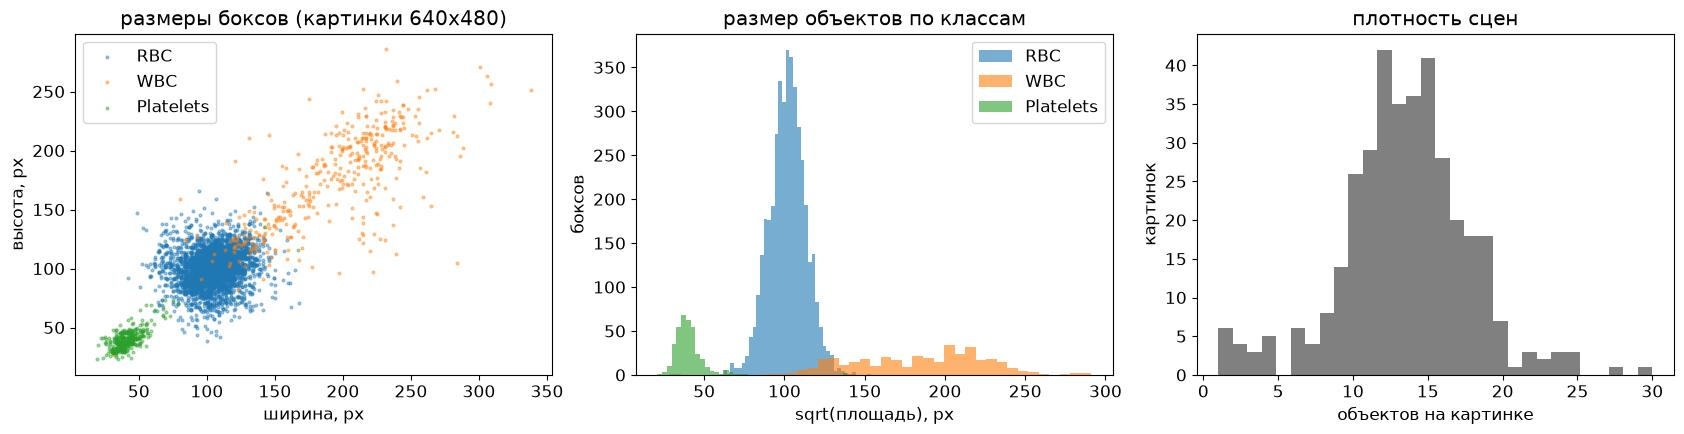

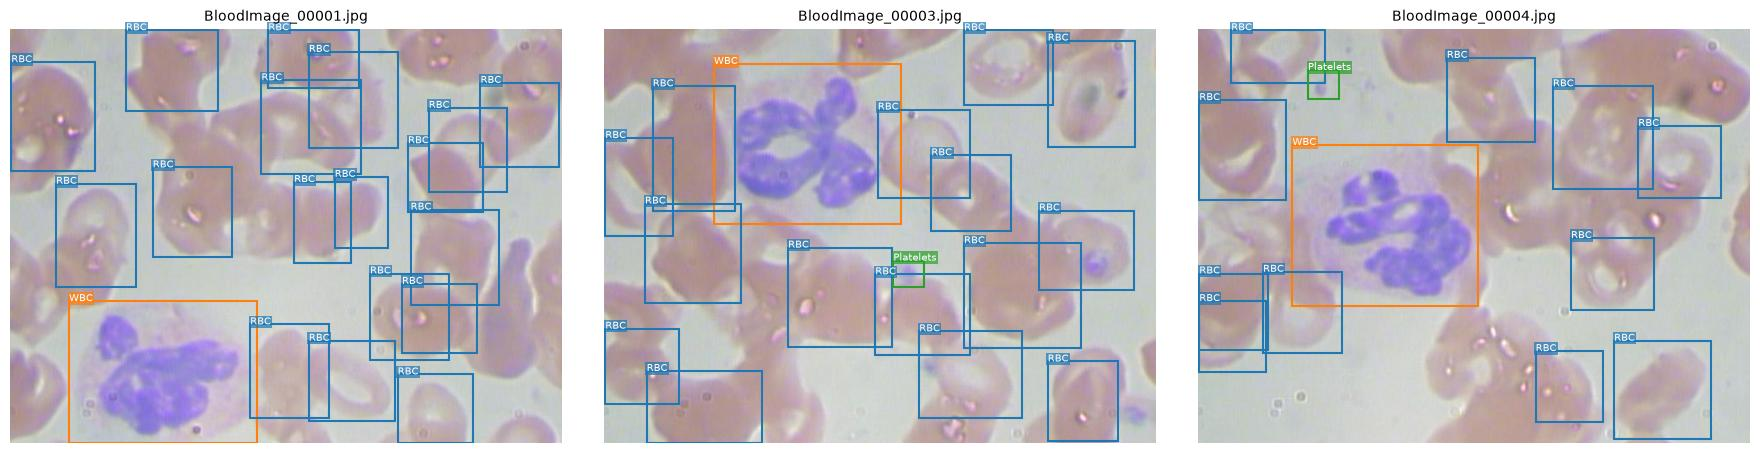

In [12]:
sizes_ok = all(Image.open(r['image']).size == (r['width'], r['height']) for recs in records.values() for r in recs)
names_in_xml = Counter(o.find('name').text for x in (BCCD_DIR / 'Annotations').glob('*.xml') for o in ET.parse(x).getroot().iter('object'))
print('размеры из XML совпадают с картинками:', sizes_ok, '| имена классов в XML как есть:', dict(names_in_xml))

print(f"\n{'split':<6} {'картинок':>9}" + ''.join(f'{c:>11}' for c in CLASSES) + f"{'объектов':>10}")
for split, recs in records.items():
    counts = np.bincount(np.concatenate([r['labels'] for r in recs]), minlength=len(CLASSES))
    print(f'{split:<6} {len(recs):>9}' + ''.join(f'{n:>11}' for n in counts) + f'{counts.sum():>10}')

all_recs = [r for recs in records.values() for r in recs]
per_img = np.array([[np.sum(r['labels'] == c) for c in range(len(CLASSES))] for r in all_recs])
print('\nобъектов на картинку: среднее {:.1f}, медиана {:.0f}, min {}, max {}'.format(
    per_img.sum(1).mean(), np.median(per_img.sum(1)), per_img.sum(1).min(), per_img.sum(1).max()))
for c, name in enumerate(CLASSES):
    print(f'  {name:<10} на картинку: среднее {per_img[:, c].mean():.2f}, картинок без класса {np.sum(per_img[:, c] == 0)}, '
          f'max {per_img[:, c].max()}')

# подозрительные дубли: пары боксов одного класса на одной картинке с IoU > 0.7
dups = Counter()
for r in all_recs:
    for c in range(len(CLASSES)):
        b = torch.as_tensor(r['boxes'][r['labels'] == c])
        iou = box_iou(b, b).triu(1) if len(b) > 1 else torch.zeros(0)
        dups[CLASSES[c]] += int((iou > 0.7).sum())
print('пары-дубли (IoU > 0.7, один класс):', dict(dups))

boxes_all = np.concatenate([r['boxes'] for r in all_recs])
labels_all = np.concatenate([r['labels'] for r in all_recs])
wh = boxes_all[:, 2:] - boxes_all[:, :2]
touch = (boxes_all[:, 0] <= 1) | (boxes_all[:, 1] <= 1) | (boxes_all[:, 2] >= 639) | (boxes_all[:, 3] >= 479)
for c, name in enumerate(CLASSES):
    m = labels_all == c
    side = np.sqrt(wh[m].prod(1))
    print(f'{name:<10} w x h медиана {np.median(wh[m, 0]):.0f} x {np.median(wh[m, 1]):.0f} px, '
          f'sqrt(площади) p5-p95: {np.percentile(side, 5):.0f}-{np.percentile(side, 95):.0f} px, у края картинки {touch[m].mean():.0%}')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for c, name in enumerate(CLASSES):
    m = labels_all == c
    axes[0].scatter(wh[m, 0], wh[m, 1], s=4, alpha=0.4, color=COLORS[c], label=name)
    axes[1].hist(np.sqrt(wh[m].prod(1)), bins=40, alpha=0.6, color=COLORS[c], label=name)
axes[0].set(xlabel='ширина, px', ylabel='высота, px', title='размеры боксов (картинки 640x480)')
axes[1].set(xlabel='sqrt(площадь), px', ylabel='боксов', title='размер объектов по классам')
axes[2].hist(per_img.sum(1), bins=30, color='gray')
axes[2].set(xlabel='объектов на картинке', ylabel='картинок', title='плотность сцен')
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, r in zip(axes, records['train'][:3]):
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, title=Path(r['image']).name)
plt.tight_layout()
plt.show()

**Ответ:** BCCD - мазки крови под микроскопом, https://github.com/Shenggan/BCCD_Dataset, лицензия MIT. 364 картинки 640x480 в VOC XML, 3 класса: RBC (эритроциты), WBC (лейкоциты), Platelets (тромбоциты). Сплиты официальные: train 205, val 87, test 72. После чистки 4886 объектов; дисбаланс сильный: RBC 4153 (85%), WBC 372, Platelets 361. Сцены плотные: в среднем 13.4 объекта на картинку, до 30, а эритроциты часто перекрываются. Тромбоциты мелкие (медиана 39x39 px против 105x101 у RBC и 201x181 у WBC) и встречаются не везде: на 163 из 364 картинок их нет. 25% боксов RBC касаются края кадра, то есть клетки обрезаны. Проблемы разметки: 2 бокса RBC нулевой площади (удалил), боксов за краем картинки 0, 8 пар почти совпадающих боксов RBC (IoU > 0.7, дубли) и неполная разметка RBC: на многих картинках часть эритроцитов, особенно у края и в скоплениях, не размечена (видно в 5.1).

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [13]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    lines = []
    for (x1, y1, x2, y2), c in zip(np.asarray(boxes, dtype=np.float64).reshape(-1, 4), np.asarray(labels).reshape(-1)):
        cx, cy = (x1 + x2) / 2 / width, (y1 + y2) / 2 / height
        w, h = (x2 - x1) / width, (y2 - y1) / height
        lines.append(f'{int(c)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n')
    return ''.join(lines)


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    rows = np.array([line.split() for line in text.splitlines() if line.strip()], dtype=np.float64).reshape(-1, 5)
    cx, cy = rows[:, 1] * width, rows[:, 2] * height
    w, h = rows[:, 3] * width, rows[:, 4] * height
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], axis=1).astype(np.float32)
    return boxes, rows[:, 0].astype(np.int64)

In [14]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [15]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    img_dir, lbl_dir = YOLO_ROOT / 'images' / split, YOLO_ROOT / 'labels' / split
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    for r in recs:
        src = Path(r['image'])
        shutil.copy(src, img_dir / src.name)
        (lbl_dir / f'{src.stem}.txt').write_text(to_yolo(r['boxes'], r['labels'], r['width'], r['height']))


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /Users/vladimirbaranov/Documents/лабы/hw2_students/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: RBC
  1: WBC
  2: Platelets



туда-обратно: 364 файлов, классы совпали, макс. расхождение координат 0.0003 px


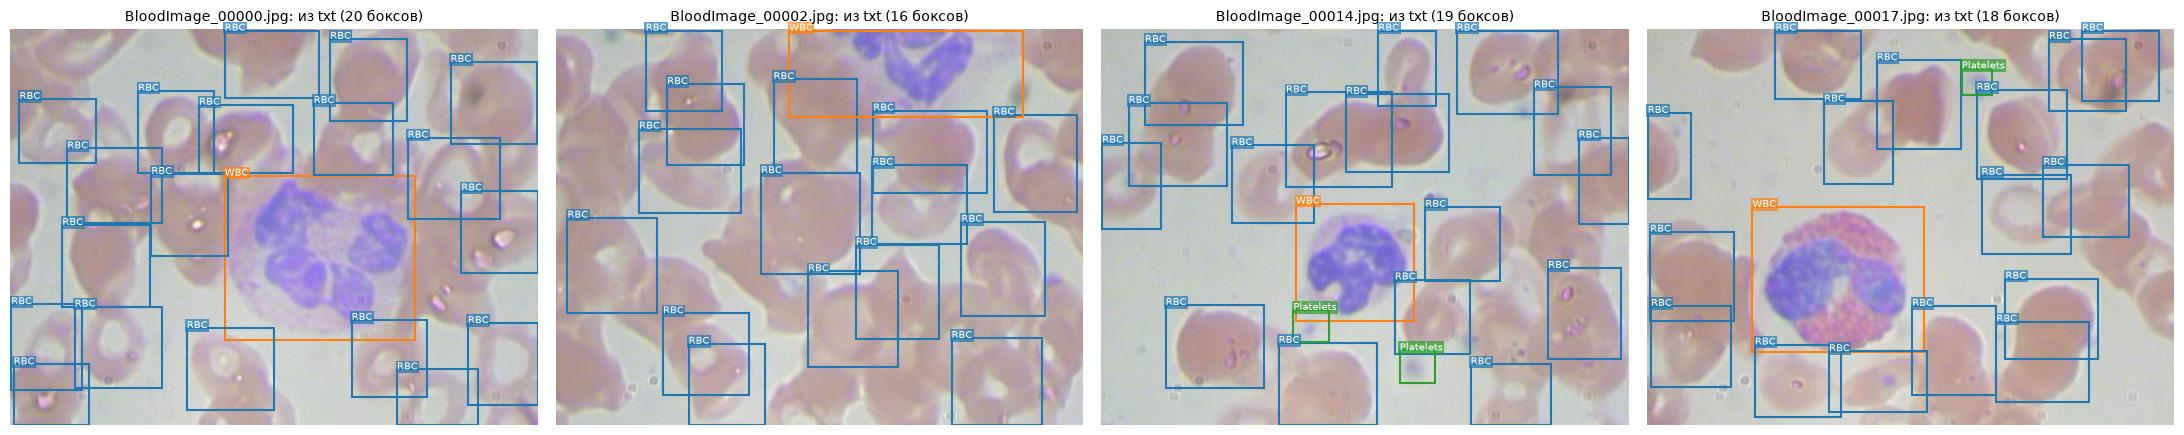

In [16]:
# 1) туда-обратно по всем выгруженным файлам: txt -> from_yolo -> сравнение с исходными боксами из XML
max_err, n_files = 0.0, 0
for split, recs in splits.items():
    for r in recs:
        stem = Path(r['image']).stem
        b, l = from_yolo((YOLO_ROOT / 'labels' / split / f'{stem}.txt').read_text(), r['width'], r['height'])
        assert (l == r['labels']).all() and b.shape == r['boxes'].shape, stem
        max_err = max(max_err, float(np.abs(b - r['boxes']).max(initial=0)))
        n_files += 1
print(f'туда-обратно: {n_files} файлов, классы совпали, макс. расхождение координат {max_err:.4f} px')

# 2) глазами: картинка из YOLO_ROOT, боксы прочитаны из txt, размер берется из самой картинки, а не из XML
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, r in zip(axes, records['val'][:4]):
    name = Path(r['image']).name
    img = Image.open(YOLO_ROOT / 'images' / 'val' / name)
    b, l = from_yolo((YOLO_ROOT / 'labels' / 'val' / f'{Path(name).stem}.txt').read_text(), *img.size)
    draw_boxes(ax, img, b, l, CLASSES, title=f'{name}: из txt ({len(l)} боксов)')
plt.tight_layout()
plt.show()

**Ответ:** Тест туда-обратно (pixels -> YOLO txt -> pixels на всех 364 файлах, макс. расхождение 0.0003 px, классы совпали) проверяет, что `to_yolo` и `from_yolo` взаимно обратны: нормировка на те же ширину и высоту, порядок cx, cy, w, h, округление до 6 знаков, пустая разметка. Он не ловит симметричные ошибки, одинаковые в обе стороны: перепутанные ширину и высоту картинки, оси x/y, неверный порядок xmin/ymin при чтении XML или сдвиг индексов классов. Такие ошибки проходят тест, и ловятся они только на картинке: боксы смещены или растянуты относительно клеток, при перепутанных осях отражены по диагонали, при размерах из XML, не совпадающих с картинкой, масштабированы. По картинкам из txt рамки легли на клетки, а размеры из XML совпали с реальными у всех картинок.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

coco_map50 = 0.000
боксов COCO при conf >= 0.25: 34 на 945 объектов разметки; {'donut': 25, 'cake': 5, 'teddy bear': 2, 'dining table': 1, 'remote': 1}
класс-агностичный AP50 COCO-модели: 0.200


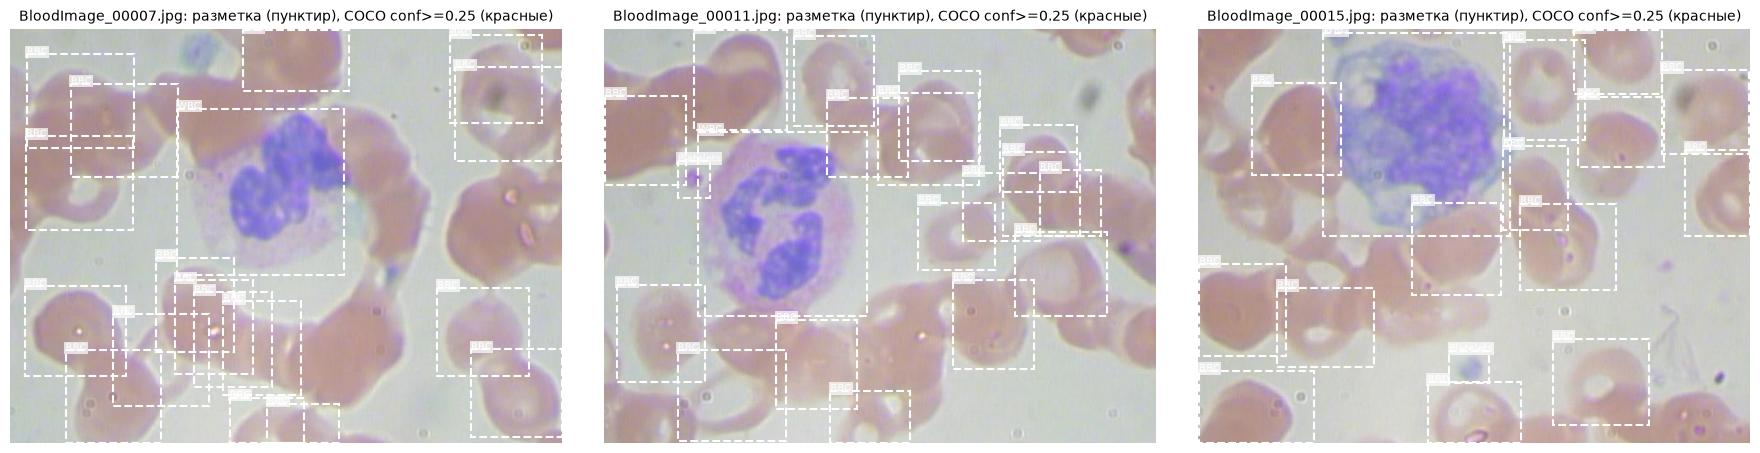

In [17]:
# COCO-модель без дообучения на FINAL_SPLIT. Клеток крови в COCO нет, совпадающих классов нет:
# переназначать нечего, все предсказания COCO-классов для наших классов - чужие, mAP50 = 0
COCO_TO_OURS = {}   # индекс класса COCO -> индекс нашего класса; пусто
coco_raw = predict_records(model_coco, records[FINAL_SPLIT], conf=0.001)
coco_preds = []
for p in coco_raw:
    keep = np.isin(p['labels'], list(COCO_TO_OURS))
    coco_preds.append(dict(boxes=p['boxes'][keep], scores=p['scores'][keep],
                           labels=np.array([COCO_TO_OURS[c] for c in p['labels'][keep]], dtype=np.int64)))
coco_map50, _ = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
print(f'coco_map50 = {coco_map50:.3f}')

# что модель видит на клетках: классы COCO при conf >= 0.25
seen = Counter(model_coco.names[int(c)] for p in coco_raw for c in p['labels'][p['scores'] >= 0.25])
n_gt = sum(len(r['labels']) for r in records[FINAL_SPLIT])
print(f'боксов COCO при conf >= 0.25: {sum(seen.values())} на {n_gt} объектов разметки;', dict(seen.most_common(8)))

# диагностика: если забыть про классы (любой бокс COCO = «клетка»), находит ли модель хотя бы объекты?
agnostic_gt = [dict(boxes=r['boxes'], labels=np.zeros_like(r['labels'])) for r in records[FINAL_SPLIT]]
agnostic_pred = [dict(boxes=p['boxes'], scores=p['scores'], labels=np.zeros_like(p['labels'])) for p in coco_raw]
print(f'класс-агностичный AP50 COCO-модели: {evaluate_map50(agnostic_pred, agnostic_gt, 1)[0]:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, r, p in zip(axes, records[FINAL_SPLIT], coco_raw):
    keep = p['scores'] >= 0.25
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='white', linestyle='--')
    draw_boxes(ax, None, p['boxes'][keep], p['labels'][keep], model_coco.names, scores=p['scores'][keep], color='red',
               title=f'{Path(r["image"]).name}: разметка (пунктир), COCO conf>=0.25 (красные)')
plt.tight_layout()
plt.show()

In [18]:
# Эвристика без нейросетей. Окраска мазка (Романовский/Райт): ядра лейкоцитов и тромбоциты - сине-фиолетовые
# (синий канал заметно выше зеленого), эритроциты - розовые (красный выше зеленого), фон - светлый и серый.
# 1) маска «фиолетового» B - G > t_purple -> связные компоненты: крупные - WBC (бокс = рамка ядра * wbc_scale,
#    цитоплазма вокруг ядра почти не окрашена), мелкие - Platelets
# 2) маска «розового» R - G > t_red без окрестности фиолетовых пятен -> дыры заливаем (у эритроцита светлый центр),
#    эритроциты слипаются, поэтому разделяем их пиками карты расстояний до фона: пик = центр клетки, значение = радиус
HEUR = dict(t_purple=35, min_area=150, wbc_area=2000, wbc_scale=1.5, plt_scale=1.2,
            t_red=12, peak_win=31, min_r=12, rbc_scale=1.0)


def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    p = HEUR
    im = np.asarray(Image.open(image_path).convert('RGB'), dtype=np.float32)
    r, g, b = im[..., 0], im[..., 1], im[..., 2]
    H, W = g.shape
    boxes, scores, labels = [], [], []

    purple = ndimage.binary_opening(b - g > p['t_purple'], iterations=2)
    comp, _ = ndimage.label(purple)
    for k, sl in enumerate(ndimage.find_objects(comp), 1):
        area = int((comp[sl] == k).sum())
        if area < p['min_area']:
            continue
        is_wbc = area >= p['wbc_area']
        scale = p['wbc_scale'] if is_wbc else p['plt_scale']
        cy, cx = (sl[0].start + sl[0].stop) / 2, (sl[1].start + sl[1].stop) / 2
        hw, hh = scale * (sl[1].stop - sl[1].start) / 2, scale * (sl[0].stop - sl[0].start) / 2
        boxes.append([cx - hw, cy - hh, cx + hw, cy + hh])
        labels.append(1 if is_wbc else 2)
        scores.append(min(area / (4 * p['wbc_area']), 1.0) if is_wbc else min(area / p['wbc_area'], 1.0))

    red = (r - g > p['t_red']) & ~ndimage.binary_dilation(purple, iterations=10)
    red = ndimage.binary_fill_holes(ndimage.binary_opening(red, iterations=2))
    dist = ndimage.distance_transform_edt(red)
    peaks = (dist == ndimage.maximum_filter(dist, size=p['peak_win'])) & (dist >= p['min_r'])
    lab, n = ndimage.label(peaks)
    if n:
        centers = ndimage.center_of_mass(peaks, lab, range(1, n + 1))
        radii = ndimage.maximum(dist, lab, range(1, n + 1))
        for (cy, cx), rad in zip(centers, radii):
            half = p['rbc_scale'] * rad
            boxes.append([cx - half, cy - half, cx + half, cy + half])
            labels.append(0)
            scores.append(min(rad / 60, 1.0))   # крупный уверенный пик - выше score

    boxes = np.clip(np.array(boxes, dtype=np.float32).reshape(-1, 4), 0, [W, H, W, H]).astype(np.float32)
    return dict(boxes=boxes, scores=np.array(scores, dtype=np.float32), labels=np.array(labels, dtype=np.int64))

In [19]:
# ваш код: параметры эвристики, если нужны (подбирать по train, не по val)
# Покоординатный подбор по подвыборке train: параметры фиолетовой маски - по среднему AP50 (WBC, Platelets),
# параметры эритроцитов - по AP50 (RBC); классы почти не влияют друг на друга. val и test не используются
HEUR_GRID = {
    't_purple': [30, 35, 40, 45, 55], 'min_area': [50, 150, 400], 'wbc_scale': [1.0, 1.1, 1.2, 1.4],
    'plt_scale': [1.6, 2.0, 2.5, 3.0], 't_red': [1, 3, 5, 8], 'rbc_scale': [1.0, 1.25, 1.5, 1.75], 'peak_win': [31, 51, 71],
}
RBC_PARAMS = {'t_red', 'peak_win', 'min_r', 'rbc_scale'}
tune_recs = records['train'][::10 if FAST_MODE else 3]
start = time.perf_counter()
for rnd in range(1 if FAST_MODE else 2):
    for key, values in HEUR_GRID.items():
        objective = []
        for v in values:
            HEUR[key] = v
            _, aps = evaluate_map50([heuristic_detect(r['image']) for r in tune_recs], tune_recs, len(CLASSES))
            objective.append(aps[0] if key in RBC_PARAMS else (aps[1] + aps[2]) / 2)
        HEUR[key] = values[int(np.argmax(objective))]
        print(f'круг {rnd}, {key:<9}', ' '.join(f'{v}:{o:.3f}' for v, o in zip(values, objective)), '->', HEUR[key])
RUN_TIMES['heuristic_tuning'] = time.perf_counter() - start
train_map, train_aps = evaluate_map50([heuristic_detect(r['image']) for r in tune_recs], tune_recs, len(CLASSES))
print(f'HEUR = {HEUR}\nmAP50 на подвыборке train ({len(tune_recs)} картинок): {train_map:.3f}',
      dict(zip(CLASSES, np.round(train_aps, 3))))

круг 0, t_purple  30:0.478 35:0.514 40:0.513 45:0.484 55:0.458 -> 35
круг 0, min_area  50:0.514 150:0.514 400:0.507 -> 50
круг 0, wbc_scale 1.0:0.479 1.1:0.521 1.2:0.547 1.4:0.538 -> 1.2
круг 0, plt_scale 1.6:0.588 2.0:0.570 2.5:0.495 3.0:0.486 -> 1.6
круг 0, t_red     1:0.219 3:0.218 5:0.200 8:0.187 -> 1
круг 0, rbc_scale 1.0:0.219 1.25:0.271 1.5:0.217 1.75:0.075 -> 1.25
круг 0, peak_win  31:0.271 51:0.268 71:0.253 -> 31
круг 1, t_purple  30:0.560 35:0.588 40:0.596 45:0.578 55:0.550 -> 40
круг 1, min_area  50:0.596 150:0.596 400:0.545 -> 50
круг 1, wbc_scale 1.0:0.447 1.1:0.564 1.2:0.596 1.4:0.596 -> 1.2
круг 1, plt_scale 1.6:0.596 2.0:0.590 2.5:0.510 3.0:0.496 -> 1.6
круг 1, t_red     1:0.281 3:0.303 5:0.307 8:0.305 -> 5
круг 1, rbc_scale 1.0:0.236 1.25:0.307 1.5:0.275 1.75:0.104 -> 1.25
круг 1, peak_win  31:0.307 51:0.310 71:0.303 -> 51
HEUR = {'t_purple': 40, 'min_area': 50, 'wbc_area': 2000, 'wbc_scale': 1.2, 'plt_scale': 1.6, 't_red': 5, 'peak_win': 51, 'min_r': 12, 'rbc_scale': 

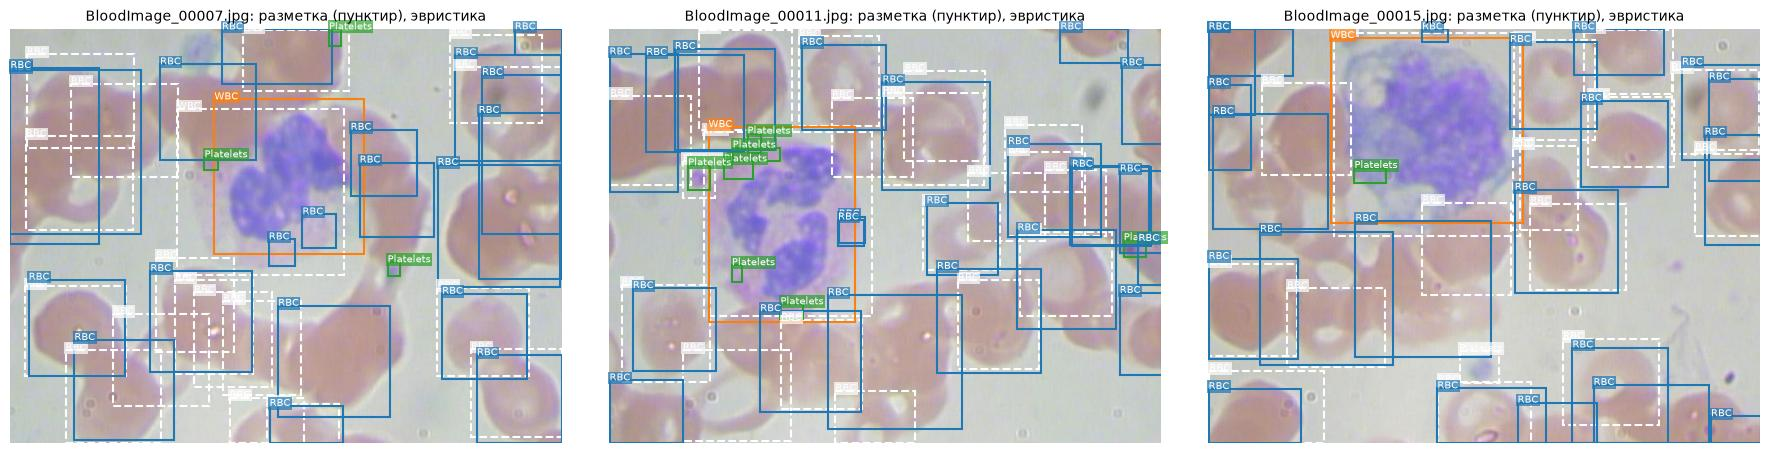

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.5087704117934941,
 'heuristic_ap50_per_class': {'RBC': 0.30905020674214956,
  'WBC': 0.9251943865818159,
  'Platelets': 0.2920666420565171}}

In [20]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, r, p in zip(axes, records[FINAL_SPLIT][:3], heuristic_preds):
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='white', linestyle='--')
    draw_boxes(ax, None, p['boxes'], p['labels'], CLASSES, title=f'{Path(r["image"]).name}: разметка (пунктир), эвристика')
plt.tight_layout()
plt.show()
BASELINE

**Ответ:** У COCO-модели mAP50 = 0: классов крови в COCO нет. При conf >= 0.25 она дала всего 34 бокса на 945 объектов, в основном `donut` (25) и `cake` (5): эритроцит с бледным центром похож на пончик. Класс-агностичный AP50 всех ее предсказаний (conf >= 0.001, без учета классов) - 0.20, то есть часть клеток модель находит как объекты, но названия классов ей негде взять. Эвристика (порог по цвету, связные компоненты, пики distance transform; параметры подобраны покоординатным перебором только на train) дает на test mAP50 0.509. Хорошо работает на WBC (AP50 0.925): крупное ярко-фиолетовое ядро отлично выделяется порогом B-G. Плохо на RBC (0.309): эритроциты бледные, слипаются, и разделить скопления пиками удается плохо. Тромбоциты (0.292) тоже фиолетовые, но мелкие, и их путают с гранулами внутри WBC и с шумом окраски.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [21]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [22]:
TRAIN_ARGS = dict(
    epochs=EPOCHS, patience=15,            # маленький датасет: сходится быстро, ранняя остановка по fitness на val
    imgsz=IMGSZ, batch=BATCH,              # 640 = родной размер кадра 640x480: тромбоциты ~38 px не уменьшаем
    optimizer='AdamW', lr0=0.001, lrf=0.05, cos_lr=True, warmup_epochs=3, weight_decay=5e-4,
    fliplr=0.5, flipud=0.5,                # у мазка под микроскопом нет «верха»: вертикальный флип допустим
    degrees=0.0,                           # поворот осе-параллельных боксов раздувает их - не используем
    scale=0.3, translate=0.1,              # увеличение микроскопа фиксировано: размер клеток почти не меняется
    hsv_h=0.02, hsv_s=0.5, hsv_v=0.3,      # разброс окраски и освещения между мазками
    mosaic=1.0, close_mosaic=10, mixup=0.0,
    seed=SEED, deterministic=True, plots=True,
)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.5, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, overlap_mas

/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/60      5.43G      1.318      2.793    0.01025        315        640: 100% ━━━━━━━━━━━━ 13/13 1.1s/it 14.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.6it/s 1.8s
                   all         87       1137      0.452      0.229      0.122      0.037

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size


/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/60      5.33G      1.269      1.775   0.009947        290        640: 100% ━━━━━━━━━━━━ 13/13 1.0s/it 13.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.6it/s 1.9s
                   all         87       1137      0.846      0.231      0.205      0.108

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size


/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (111 outputs left out)

/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      59/60      5.34G      1.008     0.5761   0.008208        188        640: 100% ━━━━━━━━━━━━ 13/13 1.2it/s 10.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.8it/s 1.7s
                   all         87       1137      0.832      0.915       0.91      0.634

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size


/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      60/60      5.33G      1.012     0.5773   0.008516        181        640: 100% ━━━━━━━━━━━━ 13/13 1.1it/s 11.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.6it/s 1.9s
                   all         87       1137      0.846      0.885      0.912      0.636

60 epochs completed in 0.235 hours.
Optimizer stripped from /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/finetune/weights/last.pt, 5.5MB
Optimizer stripped from /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/finetune/weights/best.pt, 5.5MB

Validating /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/finetune/weights/best.pt...
Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.5it/s 1.2s
                   all  

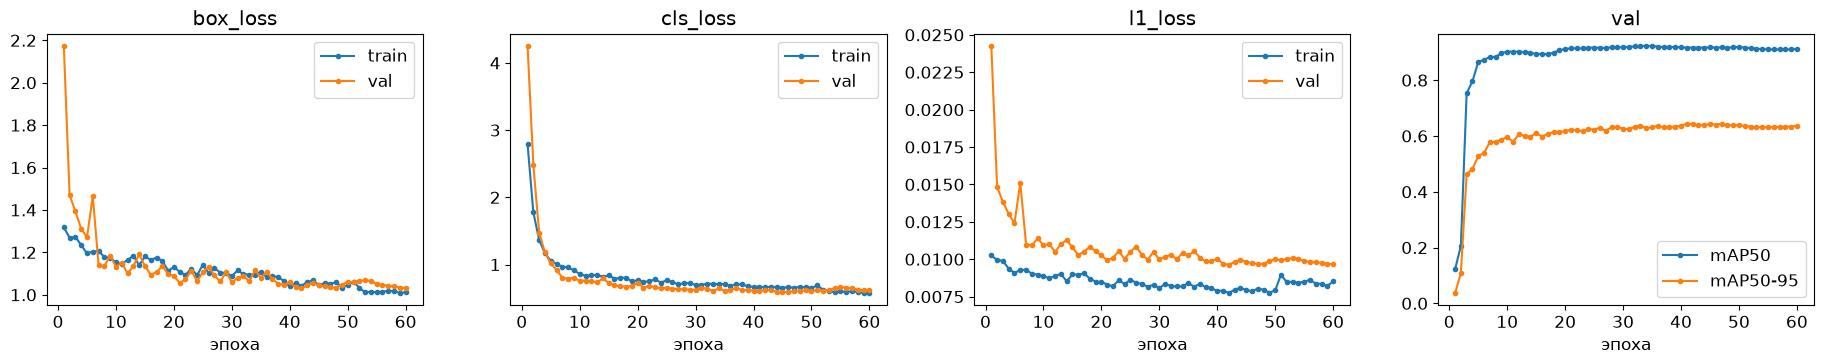

эпох пройдено 60 из 60; лучшая по val mAP50-95 - эпоха 47: mAP50 0.917, mAP50-95 0.643
время обучения 853 s (14.2 s/эпоха с валидацией), устройство mps


In [23]:
res = read_results(run_dir)
loss_names = sorted({k.split('/', 1)[1] for k in res if k.startswith(('train/', 'val/')) and k.endswith('loss')})
fig, axes = plt.subplots(1, len(loss_names) + 1, figsize=(4.6 * (len(loss_names) + 1), 3.8))
for ax, name in zip(axes, loss_names):
    for split in ('train', 'val'):
        if f'{split}/{name}' in res:
            ax.plot(res['epoch'], res[f'{split}/{name}'], marker='.', label=split)
    ax.set(title=name, xlabel='эпоха')
    ax.legend()
axes[-1].plot(res['epoch'], res['metrics/mAP50(B)'], marker='.', label='mAP50')
axes[-1].plot(res['epoch'], res['metrics/mAP50-95(B)'], marker='.', label='mAP50-95')
axes[-1].set(title='val', xlabel='эпоха')
axes[-1].legend()
plt.tight_layout()
plt.show()

best_i = int(np.argmax(res['metrics/mAP50-95(B)']))
print(f"эпох пройдено {len(res['epoch'])} из {TRAIN_ARGS['epochs']}; лучшая по val mAP50-95 - эпоха {int(res['epoch'][best_i])}: "
      f"mAP50 {res['metrics/mAP50(B)'][best_i]:.3f}, mAP50-95 {res['metrics/mAP50-95(B)'][best_i]:.3f}")
print(f'время обучения {RUN_TIMES["train"]:.0f} s ({RUN_TIMES["train"] / len(res["epoch"]):.1f} s/эпоха с валидацией), '
      f'устройство {DEVICE_NAME}')

**Ответ:** `imgsz=640` - родное разрешение 640x480: тромбоциты ~39 px, при 320 они стали бы ~20 px. `batch=16` помещается в память (MPS, на T4 тоже). AdamW с `lr0=1e-3` и косинусным спадом до 5% - аккуратное дообучение предобученной модели вместо агрессивного SGD 0.01, плюс 3 эпохи warmup. Аугментации под микроскопию: `flipud` и `fliplr` по 0.5 (у мазка нет верха и низа), `degrees=0` (поворот раздул бы выровненные по осям боксы), умеренные `hsv` (окраска плавает между препаратами), `scale=0.3`, mosaic с отключением за последние 10 эпох. 60 эпох и `patience=15` - на 205 картинках эпоха идет 14.2 s, всего 853 s. Явного переобучения нет: train cls_loss падает до конца (2.79 -> 0.58). Val cls_loss после 20-й эпохи колеблется в 0.59-0.68 (минимум 0.591 на 45-й, последняя 0.624), val box_loss - в 1.03-1.13 (последняя 1.03), вверх к концу они не уходят. Эпох хватило: mAP50 на val дошел до 0.91 к 20-й эпохе, лучший mAP50-95 0.643 на 47-й эпохе. После нее mAP50-95 держится в 0.631-0.643, а mAP50 в 0.910-0.918.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [24]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 669.3±193.1 MB/s, size: 20.1 KB)
val: Scanning /Users/vladimirbaranov/Documents/лабы/hw2_students/data/yolo/labels/val.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 52.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.4it/s 1.7s
                   all         87       1137      0.858      0.895      0.917      0.643
Speed: 0.4ms preprocess, 6.9ms inference, 0.0ms loss, 5.3ms postprocess per image
Results saved to /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/best_val
val (87)       P 0.858  R 0.895  mAP50 0.917  mAP50-95 0.643
  RBC          P 0.829  R 0.805  mAP50 0.899  mAP50-95 0.645
  WBC          P 0.982  R 1.000  mAP50 0.985  mAP50-95 0.815
  Platelets    P 0.763  R 0.88

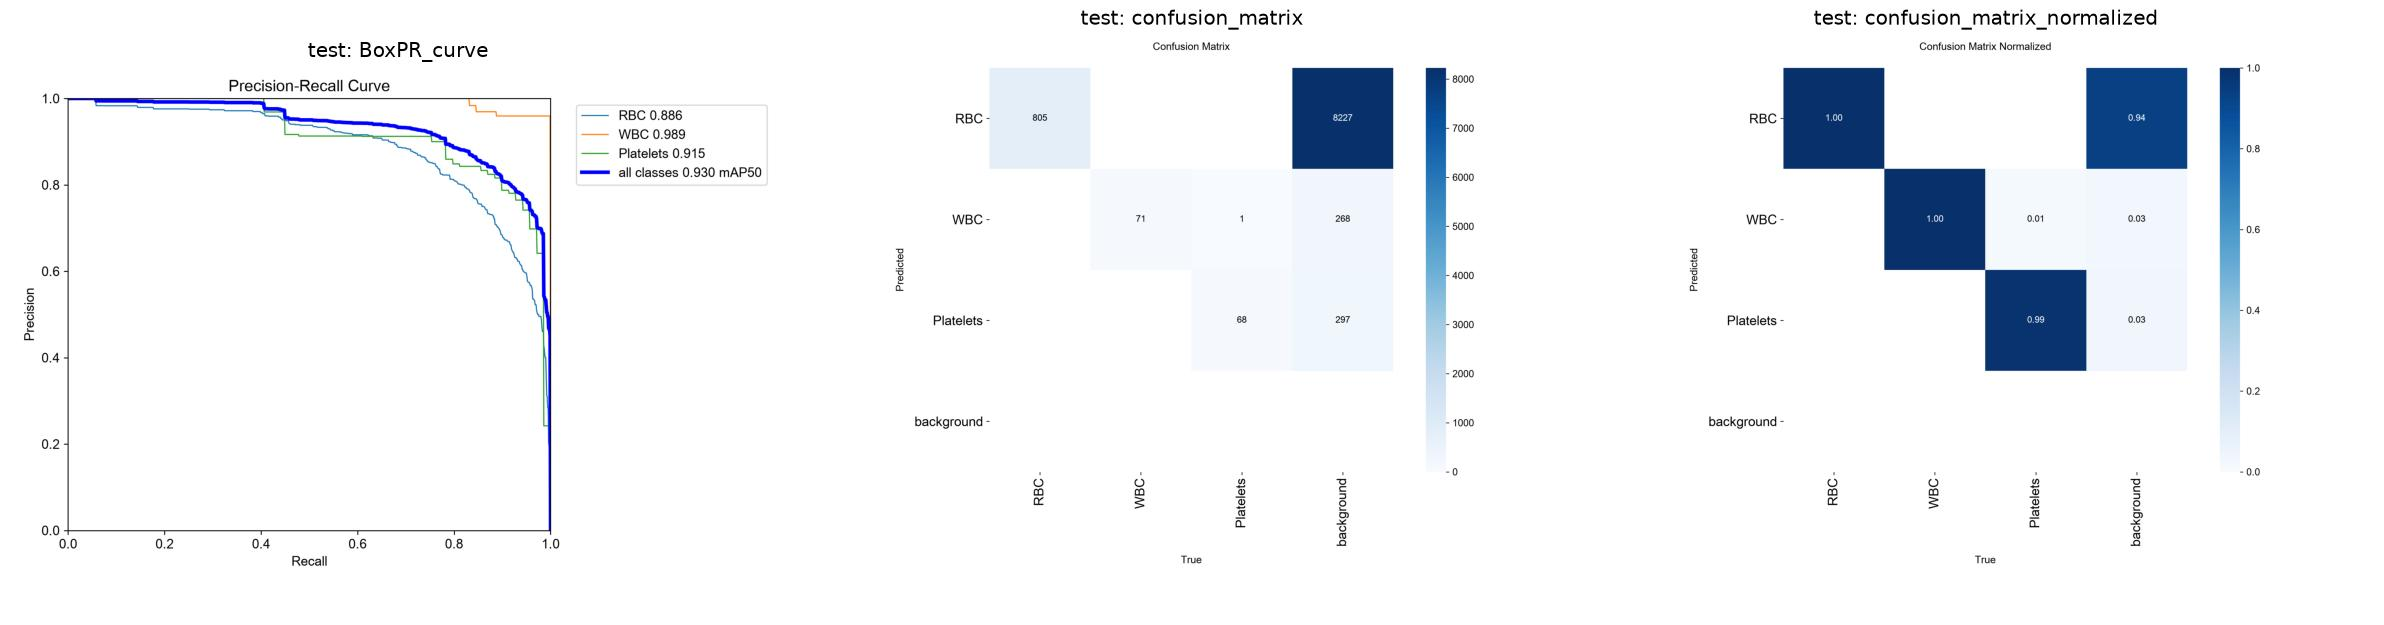

In [25]:
def summarize(m):
    # метрики ultralytics -> dict с общими и поклассовыми P, R, mAP50, mAP50-95
    per_class = {}
    for i, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(i)
        per_class[CLASSES[int(c)]] = dict(precision=float(p), recall=float(r), map50=float(ap50), map50_95=float(ap))
    return dict(map50=float(m.box.map50), map50_95=float(m.box.map), precision=float(m.box.mp), recall=float(m.box.mr),
                per_class=per_class)


def print_metrics(title, s):
    print(f"{title:<14} P {s['precision']:.3f}  R {s['recall']:.3f}  mAP50 {s['map50']:.3f}  mAP50-95 {s['map50_95']:.3f}")
    for name, c in s['per_class'].items():
        print(f"  {name:<12} P {c['precision']:.3f}  R {c['recall']:.3f}  mAP50 {c['map50']:.3f}  mAP50-95 {c['map50_95']:.3f}")


val_runs, VAL_METRICS = {}, {}
for split in dict.fromkeys(['val', FINAL_SPLIT]):
    val_runs[split] = val_metrics(best, split, f'best_{split}')
    VAL_METRICS[split] = summarize(val_runs[split])
    print_metrics(f'{split} ({len(records[split])})', VAL_METRICS[split])

FINAL = dict(split=FINAL_SPLIT, **VAL_METRICS[FINAL_SPLIT])
own_preds = predict_records(best, records[FINAL_SPLIT])
FINAL['map50_own'], own_aps = evaluate_map50(own_preds, records[FINAL_SPLIT], len(CLASSES))
print(f"\nсверка на {FINAL_SPLIT}: mAP50 ultralytics {FINAL['map50']:.4f}, evaluate_map50 {FINAL['map50_own']:.4f}; по классам",
      {c: (round(FINAL['per_class'][c]['map50'], 4), round(a, 4)) for c, a in zip(CLASSES, own_aps)})
# val по умолчанию собирает прямоугольные батчи (rect: 640x480 -> 672x512 с полями), predict идет по одной картинке 640x480.
# Сравним на одинаковом квадратном входе 640x640 (rect=False) у обоих
sq_val = summarize(val_metrics(best, FINAL_SPLIT, f'best_{FINAL_SPLIT}_square', rect=False, plots=False))
sq_own, _ = evaluate_map50(predict_records(best, records[FINAL_SPLIT], rect=False), records[FINAL_SPLIT], len(CLASSES))
print(f"тот же вход 640x640 у обоих (rect=False): mAP50 ultralytics {sq_val['map50']:.4f}, evaluate_map50 {sq_own:.4f}")

# confusion matrix ultralytics: cm[предсказанный класс, истинный класс], последний индекс - background.
# Строка background - пропуски (FN), столбец background - ложные срабатывания (FP); строится при conf val = 0.001
cm = val_runs[FINAL_SPLIT].confusion_matrix.matrix.astype(int)
cm_names = CLASSES + ['background']
print(f'\nconfusion matrix на {FINAL_SPLIT} (строки - предсказание, столбцы - разметка):')
print(' ' * 12 + ''.join(f'{n:>12}' for n in cm_names))
for i, n in enumerate(cm_names):
    print(f'{n:<12}' + ''.join(f'{v:>12}' for v in cm[i]))
print('FP (столбец background):', {c: int(cm[i, -1]) for i, c in enumerate(CLASSES)},
      '| FN (строка background):', {c: int(cm[-1, i]) for i, c in enumerate(CLASSES)},
      '| путаница классов:', int(cm[:-1, :-1].sum() - np.trace(cm[:-1, :-1])))

save_dir = Path(val_runs[FINAL_SPLIT].save_dir)
pics = [save_dir / n for n in ('BoxPR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png')]
fig, axes = plt.subplots(1, 3, figsize=(24, 6.5))
for ax, pic in zip(axes, pics):
    ax.imshow(plt.imread(pic))
    ax.set_title(f'{FINAL_SPLIT}: {pic.stem}')
    ax.set_axis_off()
plt.tight_layout()
plt.show()

In [26]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'split': 'test',
 'map50': 0.93,
 'map50_95': 0.6467,
 'precision': 0.8537,
 'recall': 0.8896,
 'map50_own': 0.896}

**Ответ:** На test mAP50 0.930, mAP50-95 0.647, P 0.854, R 0.890. Хуже всего по mAP50-95 тромбоциты (0.494 против 0.807 у WBC): объекты мелкие, и сдвиг рамки на пару пикселей заметно роняет IoU, а примеров мало (209 в train). По mAP50 хуже всего RBC (0.886): плотные перекрывающиеся скопления и неполная разметка. WBC проще всего (0.989): крупные, яркие, обычно один на картинку (в среднем 1.02, максимум 2, без WBC 6 из 364 картинок).

В матрице ultralytics строки - предсказание, столбцы - разметка. Строка background - пропуски (FN), столбец background - ложные срабатывания (FP). Между классами путаница одна: один тромбоцит предсказан как WBC. FN нет ни одного (строка background нулевая). Зато в столбце FP RBC 8227, WBC 268, Platelets 297. Матрица строится при conf val = 0.001, поэтому этот столбец - в основном низкоуверенные лишние боксы, а не только неразмеченные клетки (про боксы с уверенностью >= 0.25 - в 5.1).

mAP50-95 намного ниже mAP50, потому что усредняет IoU-пороги до 0.95, а разметка рамок RBC и тромбоцитов сама неточная на несколько пикселей.

Мой mAP50 (0.896) ниже ultralytics (0.930), сильнее всего на RBC (0.803 против 0.886). Интерполяция и сопоставление тут почти ни при чем. Разницу дает вход: `val` по умолчанию собирает прямоугольные батчи 672x512 с полями, а `predict` подает картинку 640x480 без полей. Проверка в ячейке: при одинаковом квадратном входе 640x640 (`rect=False`) у обоих ultralytics дает 0.9115, мой `evaluate_map50` - 0.9130, разница 0.0015.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [27]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(-1)
    area_a = (a[:, 2:] - a[:, :2]).prod(1)
    area_b = (b[:, 2:] - b[:, :2]).prod(1)
    return inter / (area_a[:, None] + area_b[None, :] - inter)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    pl, gl = np.asarray(pred['labels']).reshape(-1), np.asarray(gt['labels']).reshape(-1)
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    same = pl[:, None] == gl[None, :]
    found = np.zeros(len(gl), dtype=bool)    # gt стал tp
    blamed = np.zeros(len(gl), dtype=bool)   # к gt привязана ошибка класса или локализации
    cats = ['background'] * len(pl)
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        rules = (('tp', same[i] & ~found & (ious[i] >= iou_hit)),
                 ('class', ~same[i] & (ious[i] >= iou_hit)),
                 ('localization', same[i] & ~found & (ious[i] >= iou_loc) & (ious[i] < iou_hit)))
        for cat, ok in rules:
            if ok.any():
                j = int(np.argmax(np.where(ok, ious[i], -1)))   # gt с максимальным IoU среди подходящих
                (found if cat == 'tp' else blamed)[j] = True
                cats[i] = cat
                break
    return cats, np.flatnonzero(~found & ~blamed).tolist()

In [28]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


val, conf >= 0.25: 1905 предсказаний, 1137 объектов разметки
tp 1051 (92% объектов найдено); ошибок 929: class 0 (0%), localization 34 (4%), background 820 (88%), missed 75 (8%)

класс                 tp         class  localization    background        missed
RBC                  888             0            32           784            70
WBC                   87             0             0             1             0
Platelets             76             0             2            35             5
(для предсказаний - класс предсказания, для missed - класс разметки)


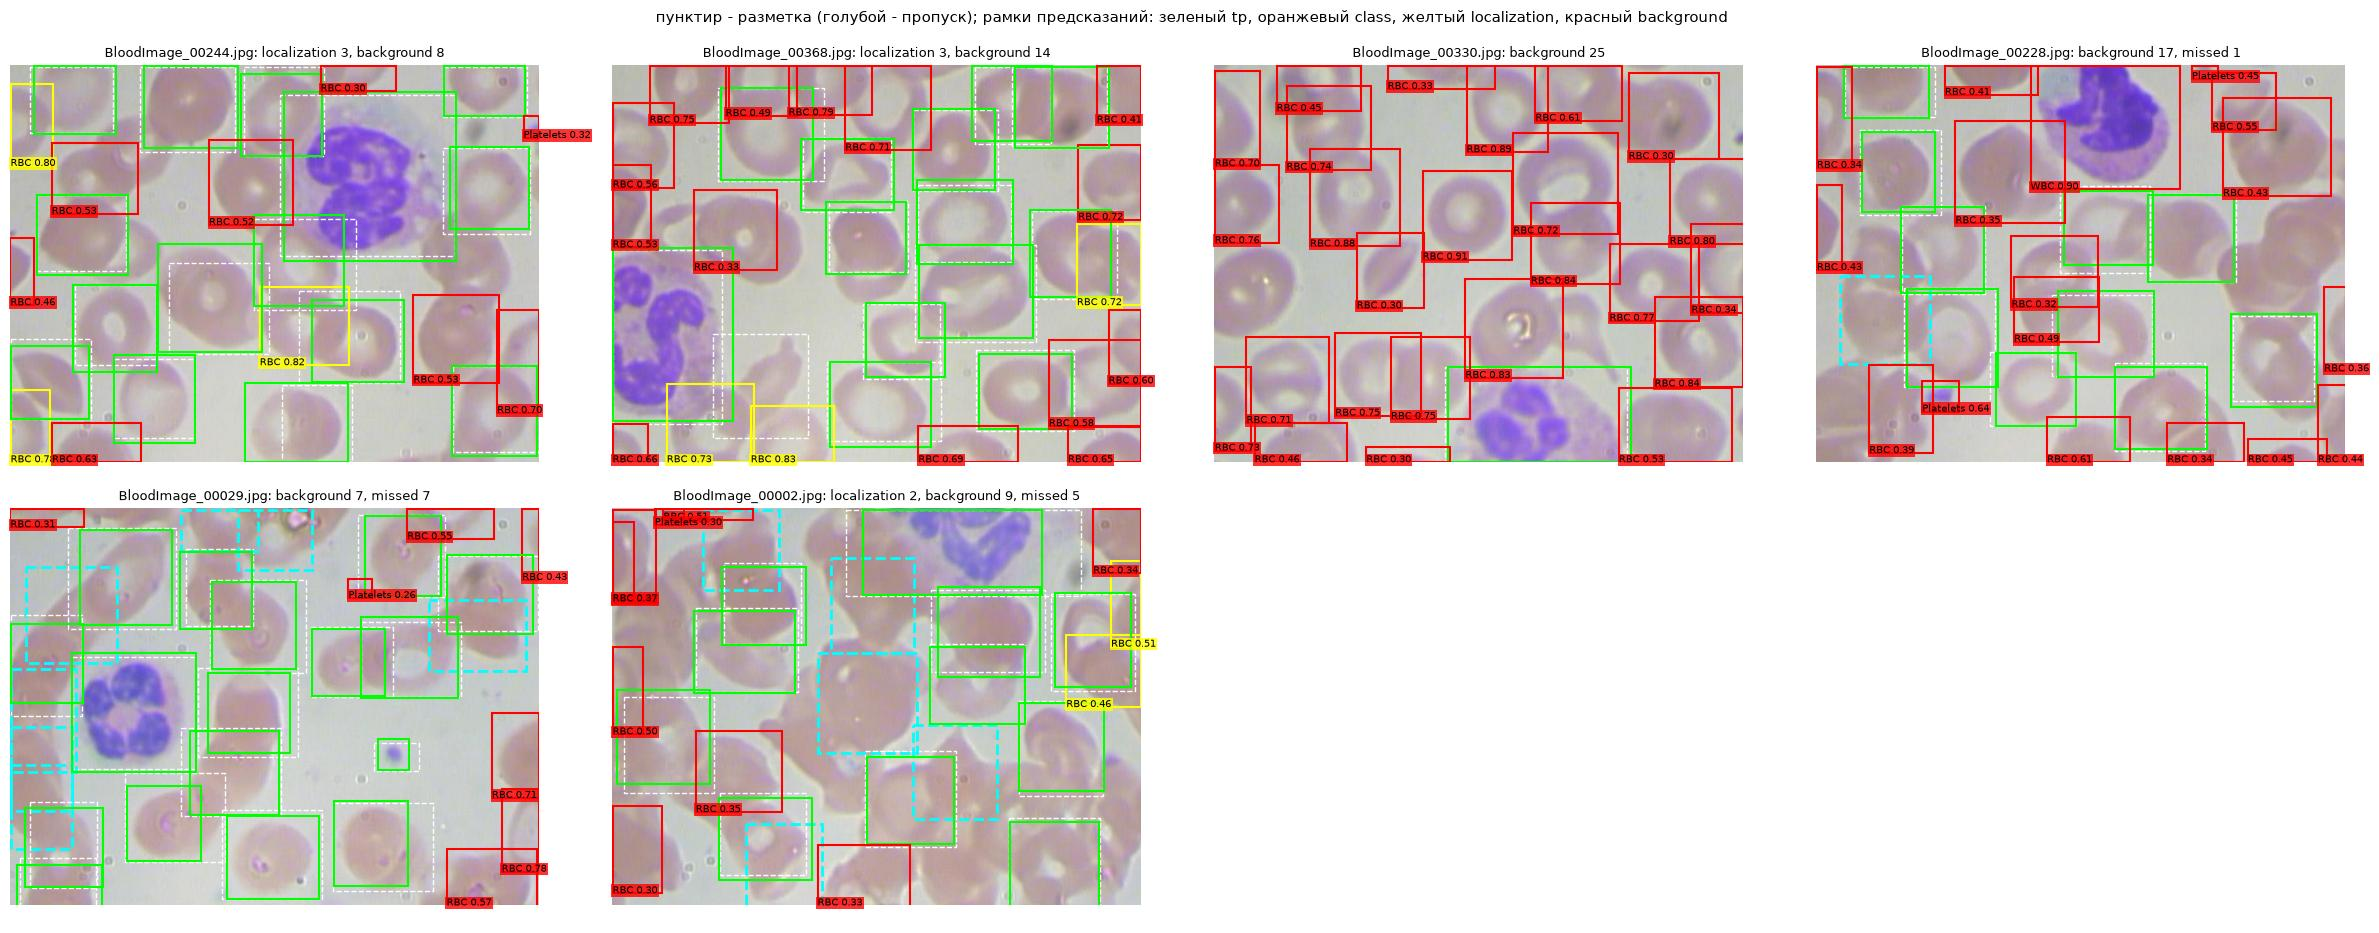

In [29]:
val_preds = predict_records(best, records['val'], conf=CONF_ERRORS)
counts, per_class, per_image = Counter(), {c: Counter() for c in CLASSES}, []
for p, g in zip(val_preds, records['val']):
    cats, missed = categorize_predictions(p, g)
    img_counts = Counter(cats) + Counter({'missed': len(missed)})
    for cat, lab in zip(cats, p['labels']):
        per_class[CLASSES[lab]][cat] += 1
    for j in missed:
        per_class[CLASSES[g['labels'][j]]]['missed'] += 1
    counts += img_counts
    per_image.append((cats, missed, img_counts))
ERRORS = {t: counts[t] for t in ERROR_TYPES}

n_err = sum(v for t, v in ERRORS.items() if t != 'tp')
n_gt = sum(len(r['labels']) for r in records['val'])
print(f'val, conf >= {CONF_ERRORS}: {sum(len(p["labels"]) for p in val_preds)} предсказаний, {n_gt} объектов разметки')
print(f"tp {ERRORS['tp']} ({ERRORS['tp'] / n_gt:.0%} объектов найдено); ошибок {n_err}:",
      ', '.join(f'{t} {ERRORS[t]} ({ERRORS[t] / max(n_err, 1):.0%})' for t in ERROR_TYPES[1:]))
print(f"\n{'класс':<10}" + ''.join(f'{t:>14}' for t in ERROR_TYPES))
for c in CLASSES:
    print(f'{c:<10}' + ''.join(f'{per_class[c][t]:>14}' for t in ERROR_TYPES))
print('(для предсказаний - класс предсказания, для missed - класс разметки)')

CAT_COLORS = {'tp': 'lime', 'class': 'orange', 'localization': 'yellow', 'background': 'red', 'missed': 'cyan'}


def show_errors(ax, k):
    r, p = records['val'][k], val_preds[k]
    cats, missed, img_counts = per_image[k]
    ax.imshow(Image.open(r['image']))
    for j, box in enumerate(r['boxes']):   # разметка: пунктир, пропуски - голубые
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linestyle='--', linewidth=2 if j in missed else 1,
                               edgecolor=CAT_COLORS['missed'] if j in missed else 'white'))
    for box, lab, s, cat in zip(p['boxes'], p['labels'], p['scores'], cats):
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=CAT_COLORS[cat], linewidth=1.5))
        if cat != 'tp':
            ax.text(x1, y2, f'{CLASSES[lab]} {s:.2f}', color='black', fontsize=7,
                    bbox=dict(facecolor=CAT_COLORS[cat], alpha=0.8, pad=1, edgecolor='none'))
    ax.set_title(f"{Path(r['image']).name}: " + ', '.join(f'{t} {img_counts[t]}' for t in ERROR_TYPES[1:] if img_counts[t]),
                 fontsize=9)
    ax.set_axis_off()


# примеры: по две картинки с наибольшим числом ошибок каждой категории (без повторов)
shown = []
for cat in ERROR_TYPES[1:]:
    ranked = sorted(range(len(per_image)), key=lambda k: -per_image[k][2][cat])
    shown += [k for k in ranked if per_image[k][2][cat] > 0 and k not in shown][:2]
fig, axes = plt.subplots(2, 4, figsize=(24, 9.5))
for ax, k in zip(axes.flat, shown):
    show_errors(ax, k)
for ax in axes.flat[len(shown):]:
    ax.set_axis_off()
fig.suptitle('пунктир - разметка (голубой - пропуск); рамки предсказаний: зеленый tp, оранжевый class, '
             'желтый localization, красный background', fontsize=11)
plt.tight_layout()
plt.show()

**Ответ:** Главная категория - background: 820 из 929 ошибок (88%) при conf >= 0.25, из них 784 приходятся на RBC. Missed - 75 (8%), localization - 34 (4%), ошибок класса нет; найдено 1051 из 1137 объектов (92%). Судя по примерам, большая часть background - ошибки разметки, а не модели. На BloodImage_00330 размечен только WBC, а 25 лишних боксов RBC (уверенность 0.30-0.91) стоят на настоящих неразмеченных эритроцитах. То же видно на BloodImage_00368 (14 лишних) и BloodImage_00228 (17 лишних): обрезанные клетки у края и клетки в скоплениях. Пропуски (BloodImage_00029, 7 missed) и ошибки локализации - в основном перекрывающиеся и обрезанные краем эритроциты, где и рамки разметки неоднозначны. Чтобы уменьшить главную категорию, я бы доразметил RBC (хотя бы val и test, иначе метрика штрафует правильные ответы) и убрал дубли разметки. Порог `conf` я бы выбирал по F1 на val, а не брал дефолт 0.25: по 6.5 максимум F1 при conf 0.44, и лишних слабых боксов там меньше.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [30]:
# абляция: imgsz IMGSZ против IMGSZ // 2, остальное как в TRAIN_ARGS. Ожидаем, что сильнее всего пострадают тромбоциты
ABL_IMGSZ = IMGSZ // 2
_, RUN_TIMES['ablation_train'], run_dir_abl = train_yolo(f'ablation_imgsz{ABL_IMGSZ}', **{**TRAIN_ARGS, 'imgsz': ABL_IMGSZ})
best_abl = YOLO(run_dir_abl / 'weights' / 'best.pt')
abl_val = summarize(best_abl.val(data=str(DATA_YAML), split='val', imgsz=ABL_IMGSZ, batch=BATCH, device=DEVICE,
                                 workers=WORKERS, project=str(RUNS.resolve()), name='ablation_val', exist_ok=True, verbose=False))


def ablation_row(s, train_time, latency):
    return dict(map50=s['map50'], map50_95=s['map50_95'], train_time_sec=train_time, latency_ms=latency,
                ap50_per_class={c: v['map50'] for c, v in s['per_class'].items()},
                ap50_95_per_class={c: v['map50_95'] for c, v in s['per_class'].items()})


ABLATION = dict(param='imgsz', values=[IMGSZ, ABL_IMGSZ], split='val', results={
    IMGSZ: ablation_row(VAL_METRICS['val'], RUN_TIMES['train'], measure_latency(YOLO(run_dir / 'weights' / 'best.pt'))),
    ABL_IMGSZ: ablation_row(abl_val, RUN_TIMES['ablation_train'], measure_latency(best_abl, imgsz=ABL_IMGSZ)),
})
for size, row in ABLATION['results'].items():
    print(f"imgsz {size}: mAP50 {row['map50']:.3f}, mAP50-95 {row['map50_95']:.3f}, обучение {row['train_time_sec']:.0f} s, "
          f"задержка {row['latency_ms']:.1f} мс")
    print('   AP50 по классам', {c: round(v, 3) for c, v in row['ap50_per_class'].items()},
          '| AP50-95 по классам', {c: round(v, 3) for c, v in row['ap50_95_per_class'].items()})

Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.5, hsv_v=0.3, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ablation_imgsz320, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, ov

/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/60      2.33G      1.454       2.96    0.01146        316        320: 100% ━━━━━━━━━━━━ 13/13 2.7it/s 4.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.7it/s 1.1s
                   all         87       1137       0.79      0.194      0.135     0.0535

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/60      2.34G      1.533      2.528    0.01365        314        320: 0% ──────────── 0/13  0.9s

/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/60      2.32G      1.343      2.256    0.01058        289        320: 100% ━━━━━━━━━━━━ 13/13 2.9it/s 4.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.6it/s 1.2s
                   all         87       1137      0.525      0.215      0.216      0.102

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/60      2.36G      1.291      2.054    0.01041        330        320: 0% ──────────── 0/13  1.0s

/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (111 outputs left out)

/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      59/60      2.39G      1.076     0.8233   0.008912        188        320: 100% ━━━━━━━━━━━━ 13/13 3.2it/s 4.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.2it/s 0.9s
                   all         87       1137       0.86      0.892      0.905       0.63

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      60/60      2.37G     0.9718      0.738   0.008523        232        320: 0% ──────────── 0/13  0.7s

/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      60/60      2.38G      1.066     0.8204   0.009057        181        320: 100% ━━━━━━━━━━━━ 13/13 3.5it/s 3.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.0it/s 1.0s
                   all         87       1137      0.862      0.887      0.904      0.629

60 epochs completed in 0.106 hours.
Optimizer stripped from /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/ablation_imgsz320/weights/last.pt, 5.4MB
Optimizer stripped from /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/ablation_imgsz320/weights/best.pt, 5.4MB

Validating /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/ablation_imgsz320/weights/best.pt...
Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.1it/s 1.0

**Ответ:** Менял `imgsz`: 640 против 320, остальное как в 4.1. На val при 320 mAP50 0.909 против 0.917 (на 0.0082 ниже), mAP50-95 0.633 против 0.643 (на 0.0101 ниже). По AP50 сильнее всего просели тромбоциты (0.848 против 0.868): при 320 они ~20 px и теряют детали. По AP50-95 сильнее просели RBC (0.628 против 0.645), у тромбоцитов 0.461 против 0.470. RBC по AP50 чуть ниже (0.891 против 0.899), WBC не изменились (AP50 0.989 против 0.985). Зато обучение в 2.2 раза быстрее (385 s против 853 s), а задержка на MPS 8.1 против 11.6 мс (замеры на MPS шумят на ~0.5 мс: в 6.4 та же модель дала 11.1 мс). На таком маленьком датасете 640 стоит своих денег, тем более что разница во времени - 8 минут. Если важна скорость инференса и тромбоциты не главная цель, 320 почти без потерь. Разница ~0.01 mAP сравнима с шумом от одного seed на 87 картинках val.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** Дообучение `yolo26n` дало на test mAP50 0.930 и mAP50-95 0.647 против 0 у COCO-модели и 0.509 у цветовой эвристики. Эвристика хороша только на WBC (0.925), так что основной выигрыш от сети - на RBC и тромбоцитах. Обучение заняло 14 минут на M3 Pro, переобучения по кривым нет. Сравнение `imgsz` 640 и 320 показало, что для мелких тромбоцитов разрешение важно, но выигрыш небольшой (0.917 против 0.909 на val). RT-DETR-l после исправления настроек дошел до mAP50 0.887 на val (YOLO на val 0.917), но при этом в 13 раз больше и в 4.6 раза медленнее YOLO. Главная проблема - не модель, а разметка: 88% ошибок - «лишние» боксы, и в основном это неразмеченные эритроциты, поэтому точность по RBC занижена. Ограничения: val 87 и test 72 картинки из одного источника, один seed (разницы в 0.01 могут быть шумом), устойчивость к шуму низкая (mAP50 0.593), нет проверки на мазках другой окраски и микроскопа. Дальше я бы доразметил RBC, обучил несколько seed для доверительных интервалов и добавил аугментации шума.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [31]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'bonus_metrics.json', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [32]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Не выполнялось: задача требует ручной разметки 50+ картинок, ее нужно делать вручную, поэтому `6.1` не включен в `BONUS_TASKS`.

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.5, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr, nbs=4, nms=None, opset=None, optimize=False, optimizer=AdamW, overlap_mask=

/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: grid_sampler_2d_backward_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic sup

       1/25      7.89G      1.106      3.098     0.7592         20        640: 100% ━━━━━━━━━━━━ 52/52 1.2s/it 1:01
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.2it/s 5.1s
                   all         87       1137      0.378      0.152     0.0513     0.0302

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: grid_sampler_2d_backward_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic sup

       2/25      7.88G     0.5352     0.8202     0.2976         26        640: 100% ━━━━━━━━━━━━ 52/52 1.1s/it 58.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.2it/s 5.1s
                   all         87       1137      0.533       0.86      0.697      0.467

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: grid_sampler_2d_backward_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic sup

... (41 outputs left out)

/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: grid_sampler_2d_backward_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic sup

      24/25      7.82G     0.2705     0.4296     0.1405         10        640: 100% ━━━━━━━━━━━━ 52/52 1.1s/it 55.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.2it/s 4.9s
                   all         87       1137      0.817      0.888      0.881      0.628

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      25/25      6.81G      0.248     0.4658     0.1582         41        640: 0% ──────────── 0/52  1.6s

/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/vladimirbaranov/Documents/лабы/hw2_students/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: grid_sampler_2d_backward_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic sup

      25/25      7.83G     0.2678     0.4295     0.1394         11        640: 100% ━━━━━━━━━━━━ 52/52 1.1s/it 55.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.2it/s 5.0s
                   all         87       1137      0.819      0.889      0.881      0.628

25 epochs completed in 0.447 hours.
Optimizer stripped from /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/rtdetr/weights/last.pt, 66.3MB
Optimizer stripped from /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/rtdetr/weights/best.pt, 66.3MB

Validating /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/rtdetr/weights/best.pt...
Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
rt-detr-l summary (fused): 315 layers, 31,989,905 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.6it/s 4.2s
                   

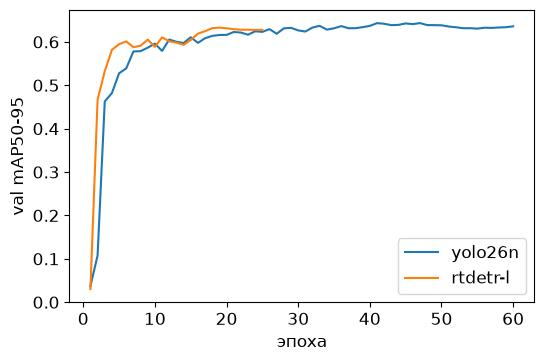

In [33]:
if '6.2' in BONUS_TASKS:
    import gc
    from ultralytics import RTDETR


    def free_memory(trainer=None):
        # кэш MPS-аллокатора растет от эпохи к эпохе; на 18 ГБ unified memory это кончается свопом
        gc.collect()
        if DEVICE == 'mps':
            torch.mps.empty_cache()


    del model_coco, arch, model_ft, best_abl   # дальше не нужны, освобождаем память под RT-DETR
    free_memory()
    # 25 эпох: в пробе (5 эпох, полный train) val mAP50 вырос до 0.80, эпоха ~80 s; 40 эпох не уложились бы в бюджет.
    # batch 4: при batch 8 и 640 px память MPS росла 13 -> 15 ГБ и уходила в своп.
    # nbs=4: иначе ultralytics копит градиент до nominal batch 64 (accumulate 16) - шагов оптимизатора в 16 раз меньше,
    # и за 40 эпох веса почти не сдвигаются от COCO, головы классов остаются случайными.
    # lr0=1e-4 - типичный lr AdamW для DETR-моделей (у YOLO 1e-3).
    # warmup_bias_lr=0: при явном optimizer='AdamW' ultralytics оставляет дефолт 0.1, это ломает bias трансформера
    RTDETR_ARGS = {**TRAIN_ARGS, 'epochs': EPOCHS if FAST_MODE else 25, 'batch': 4, 'nbs': 4, 'lr0': 1e-4,
                   'warmup_epochs': 2, 'warmup_bias_lr': 0.0}
    rtdetr = RTDETR('rtdetr-l.pt')
    rtdetr.add_callback('on_fit_epoch_end', free_memory)
    rtdetr_params = count_params(rtdetr)
    start = time.perf_counter()
    rtdetr.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name='rtdetr',
                 exist_ok=True, verbose=False, **RTDETR_ARGS)
    RUN_TIMES['rtdetr_train'] = time.perf_counter() - start
    rtdetr_dir = Path(rtdetr.trainer.save_dir)
    rt_res = read_results(rtdetr_dir)
    rt_best = RTDETR(rtdetr_dir / 'weights' / 'best.pt')
    rt_val = summarize(rt_best.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=RTDETR_ARGS['batch'], device=DEVICE,
                                   workers=WORKERS, project=str(RUNS.resolve()), name='rtdetr_val', exist_ok=True, verbose=False))
    RTDETR_CMP = {
        'yolo26n': dict(params=MODEL_INFO['params'], train_time_sec=RUN_TIMES['train'], epochs=len(res['epoch']),
                        latency_ms=ABLATION['results'][IMGSZ]['latency_ms'], **VAL_METRICS['val']),
        'rtdetr-l': dict(params=rtdetr_params, train_time_sec=RUN_TIMES['rtdetr_train'], epochs=len(rt_res['epoch']),
                         latency_ms=measure_latency(rt_best), **rt_val),
    }
    for name, row in RTDETR_CMP.items():
        print(f"{name:<9} params {row['params'] / 1e6:5.1f}M, эпох {row['epochs']}, обучение {row['train_time_sec']:.0f} s, "
              f"задержка {row['latency_ms']:.1f} мс | val mAP50 {row['map50']:.3f}, mAP50-95 {row['map50_95']:.3f} | AP50-95:",
              {c: round(v['map50_95'], 3) for c, v in row['per_class'].items()})
    plt.figure(figsize=(6, 3.8))
    plt.plot(res['epoch'], res['metrics/mAP50-95(B)'], label='yolo26n')
    plt.plot(rt_res['epoch'], rt_res['metrics/mAP50-95(B)'], label='rtdetr-l')
    plt.xlabel('эпоха')
    plt.ylabel('val mAP50-95')
    plt.legend()
    plt.show()

**Ответ:** Сравнение на val: YOLO26n - 2.6M параметров, 60 эпох за 853 s, задержка 11.6 мс (в 6.4 на MPS 11.1 мс - шум замера), mAP50 0.917 / mAP50-95 0.643. RT-DETR-l - 33.0M параметров (в 12.8 раза больше), 25 эпох за 1617 s (65 s/эпоха), задержка 53.4 мс (в 4.6 раза медленнее), mAP50 0.887 / mAP50-95 0.633. По классам (AP50-95) RT-DETR хуже на RBC (0.617 против 0.645) и тромбоцитах (0.458 против 0.470). Precision у него ниже (0.812 против 0.858).

Выигрыш у RT-DETR небольшой: AP50-95 на WBC 0.823 против 0.815. На RBC recall выше (0.845 против 0.805), но ценой precision (0.673 против 0.829; поклассовые P и R RBC - по `artifacts/bonus_metrics.json`, в выводе ячейки их нет). В целом при размере в 13 раз больше и вдвое большем времени обучения он немного хуже YOLO. Эпох у него меньше (25 против 60, бюджет), но лучшая эпоха - 19-я, так что дело не в недообучении.

В прошлом прогоне этого ноутбука (`batch=4`, `nbs=64` по умолчанию; в текущих outputs его нет) RT-DETR не сошелся: mAP50 0.12 на val, ранняя остановка на 37-й эпохе. Причина была в настройках. Ultralytics копит градиент до nominal batch `nbs=64`, то есть 16 батчей на шаг: за 37 эпох вышло около 130 шагов оптимизатора, и головы классов остались почти случайными. Кроме того, при явном `optimizer='AdamW'` остается `warmup_bias_lr=0.1`. С `nbs=4` и `warmup_bias_lr=0` train cls_loss падает с 3.10 до 0.43. Пробы на 4-5 эпох я делал отдельным скриптом вне ноутбука: без `nbs=4` mAP50 оставался ~0.04, с ним после 5 эпох было 0.80.

RT-DETR я бы выбрал на GPU с запасом по вычислениям, для плотных перекрывающихся объектов, где NMS ошибается, и при большом датасете: трансформеру нужно больше данных и эпох. Для BCCD и быстрого инференса YOLO26n выгоднее по всем пунктам.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1528.9±251.6 MB/s, size: 30.8 KB)
val: Scanning /Users/vladimirbaranov/Documents/лабы/hw2_students/data/yolo/labels/val_dark... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 6.3Kit/s 0.0s
val: New cache created: /Users/vladimirbaranov/Documents/лабы/hw2_students/data/yolo/labels/val_dark.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 6.0it/s 1.0s
                   all         87       1137      0.866      0.708      0.799      0.537
Speed: 0.1ms preprocess, 5.3ms inference, 0.0ms loss, 3.5ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms

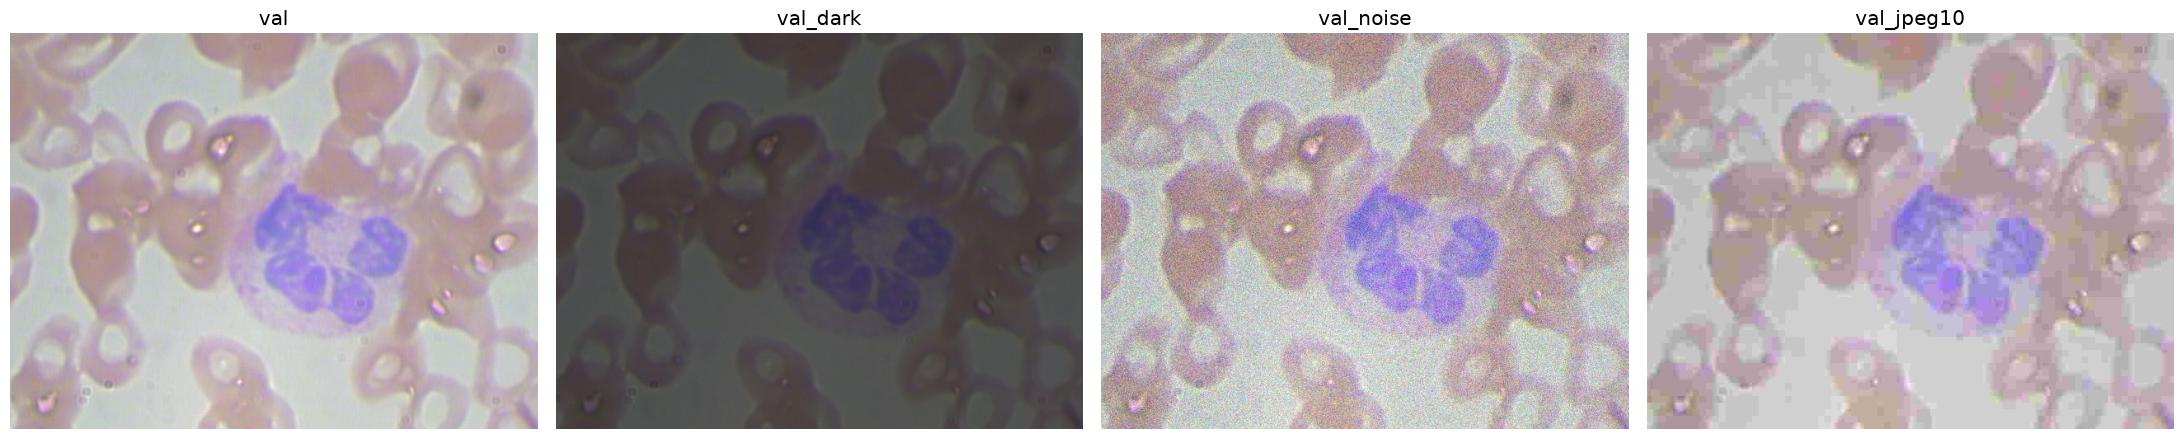

In [34]:
if '6.3' in BONUS_TASKS:
    noise_rng = np.random.default_rng(SEED)


    def darken(im):
        return Image.fromarray((np.asarray(im, dtype=np.float32) * 0.4).astype(np.uint8)), 95


    def add_noise(im):
        a = np.asarray(im, dtype=np.float32)
        return Image.fromarray(np.clip(a + noise_rng.normal(0, 25, a.shape), 0, 255).astype(np.uint8)), 95


    DISTORTIONS = {'dark': darken, 'noise': add_noise, 'jpeg10': lambda im: (im, 10)}   # -> (картинка, качество JPEG)
    SHIFT = {'clean': VAL_METRICS['val']}
    for kind, distort in DISTORTIONS.items():
        split = f'val_{kind}'
        (YOLO_ROOT / 'images' / split).mkdir(parents=True, exist_ok=True)
        shutil.copytree(YOLO_ROOT / 'labels' / 'val', YOLO_ROOT / 'labels' / split, dirs_exist_ok=True)
        for r in records['val']:
            im, quality = distort(Image.open(r['image']).convert('RGB'))
            im.save(YOLO_ROOT / 'images' / split / Path(r['image']).name, quality=quality)
        yaml_path = YOLO_ROOT / f'data_{split}.yaml'
        yaml_path.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\ntrain: images/train\nval: images/{split}\n'
                             + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
        SHIFT[kind] = summarize(best.val(data=str(yaml_path), split='val', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                                         workers=WORKERS, project=str(RUNS.resolve()), name=f'shift_{kind}', exist_ok=True,
                                         verbose=False, plots=False))
    print(f"{'val':<8} {'mAP50':>7} {'mAP50-95':>9}" + ''.join(f'{c + " AP50":>16}' for c in CLASSES))
    for kind, s in SHIFT.items():
        print(f"{kind:<8} {s['map50']:>7.3f} {s['map50_95']:>9.3f}"
              + ''.join(f"{s['per_class'][c]['map50']:>16.3f}" for c in CLASSES))
    print('recall по классам:', {kind: {c: round(s['per_class'][c]['recall'], 3) for c in CLASSES} for kind, s in SHIFT.items()})
    name = Path(records['val'][0]['image']).name
    fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
    for ax, kind in zip(axes, ['val'] + [f'val_{k}' for k in DISTORTIONS]):
        ax.imshow(Image.open(YOLO_ROOT / 'images' / kind / name))
        ax.set_title(kind)
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

**Ответ:** Сильнее всего бьет гауссов шум (σ = 25): mAP50 на val 0.917 -> 0.593, mAP50-95 0.643 -> 0.338. Почти полностью теряются RBC (AP50 0.899 -> 0.380, recall 0.805 -> 0.027): бледный эритроцит на шуме сливается с фоном. Тромбоциты падают до 0.426 (recall 0.254), а WBC держатся (0.973): яркое ядро шум не прячет. Затемнение (x0.4) снижает mAP50 до 0.799, сильнее всего у тромбоцитов (AP50 0.644, recall 0.457) и RBC (0.790). JPEG с качеством 10 - 0.828, заметно страдает RBC (AP50 0.704, recall 0.563). Помогли бы аугментации шума и размытия (GaussNoise, Blur через albumentations), более широкий `hsv_v` (например, 0.6) и JPEG-сжатие при обучении. WBC в аугментациях не нуждаются, слабое место - бледные и мелкие классы.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [35]:
if '6.4' in BONUS_TASKS:
    best_path = run_dir / 'weights' / 'best.pt'
    onnx_path = YOLO(best_path).export(format='onnx', imgsz=IMGSZ)   # нужны onnx и onnxruntime
    # для каждого замера - свежий объект: predictor ultralytics запоминает устройство первого вызова
    SPEED = {
        f'pytorch {DEVICE_NAME}': measure_latency(YOLO(best_path)),
        'pytorch cpu': measure_latency(YOLO(best_path), device='cpu'),
        'onnxruntime cpu': measure_latency(YOLO(onnx_path, task='detect'), device='cpu'),
    }
    onnx_val = summarize(YOLO(onnx_path, task='detect').val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=1, device='cpu',
                                                            project=str(RUNS.resolve()), name='onnx_val', exist_ok=True,
                                                            verbose=False, plots=False))
    # ONNX со статичным входом валидируется квадратным letterbox 640x640 (rect=False для не-pt моделей),
    # PyTorch по умолчанию - прямоугольными батчами. Для честного сравнения - PyTorch в тех же условиях
    pt_square = summarize(YOLO(best_path).val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=1, device='cpu', rect=False,
                                              project=str(RUNS.resolve()), name='pt_square_val', exist_ok=True,
                                              verbose=False, plots=False))
    print(f'задержка на картинку {IMGSZ}x{IMGSZ}, мс (среднее по 20 после 5 прогревочных):')
    for name, ms in SPEED.items():
        print(f"  {name:<18} {ms:6.1f}  (x{SPEED['pytorch cpu'] / ms:.2f} к pytorch cpu)")
    print(f"val mAP50: pytorch {VAL_METRICS['val']['map50']:.4f} -> onnx {onnx_val['map50']:.4f}; "
          f"mAP50-95: {VAL_METRICS['val']['map50_95']:.4f} -> {onnx_val['map50_95']:.4f}; "
          f"размер: pt {best_path.stat().st_size / 2**20:.1f} МБ, onnx {Path(onnx_path).stat().st_size / 2**20:.1f} МБ")
    for title, s in ((f'pytorch {DEVICE_NAME} rect', VAL_METRICS['val']), ('pytorch cpu 640x640', pt_square),
                     ('onnx cpu 640x640', onnx_val)):
        print_metrics(title, s)

Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 CPU (Apple M3 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/finetune/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 1.4s, saved as '/Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/finetune/weights/best.onnx' (9.4 MB)

Export complete (1.5s)
Results saved to /Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/finetune/weights/best.onnx
Predict:         yolo predict task=detect model=/Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/finetune/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/Users/vladimirbaranov/Documents/лабы/hw2_students/runs_hw2/finetune/weights/best.onnx imgsz=640 data=data/yolo/

**Ответ:** Задержка на картинку 640x640 (среднее по 20 после 5 прогревочных, M3 Pro): PyTorch CPU 33.4 мс, ONNX Runtime CPU 20.0 мс, то есть на CPU ускорение в 1.67 раза. PyTorch на MPS - 11.1 мс. Ускорение - за счет статичного графа: ONNX Runtime сливает операции и применяет оптимизированные CPU-ядра без накладных расходов Python и eager-режима PyTorch, плюс граф дополнительно упростил `onnxslim`. В качестве экспорт ничего не стоит. ONNX со статичным входом валидируется квадратным letterbox 640x640, и PyTorch на том же входе (`rect=False`) дает ровно те же числа: mAP50 0.890, mAP50-95 0.625, совпадают и метрики по классам. Падение 0.917 -> 0.890 против обычной PyTorch-валидации - от формы входа (прямоугольные батчи против квадрата с серыми полями), сильнее всего у RBC: precision 0.829 -> 0.724, AP50 0.899 -> 0.833. Файл вырос с 5.2 до 9.4 МБ.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1107.4±150.9 MB/s, size: 20.7 KB)
val: Scanning /Users/vladimirbaranov/Documents/лабы/hw2_students/data/yolo/labels/val.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 6.1it/s 1.0s
                   all         87       1137      0.857      0.896       0.91      0.636
Speed: 2.0ms preprocess, 3.3ms inference, 0.0ms loss, 3.5ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.12.6 torch-2.15.0 MPS (Apple M3 Pro)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1078.8±138.9 MB/s, size: 20.8 KB)
val: Scanning /Users/vladimirbaranov/Documents/лабы/hw2_students/data/yo

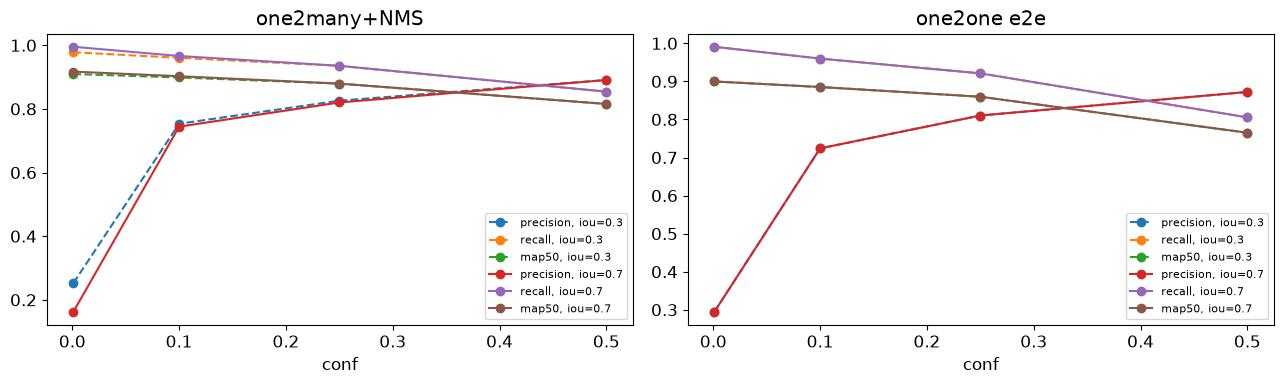

In [36]:
if '6.5' in BONUS_TASKS:
    THRESH, PX = [], np.linspace(0, 1, 1000)
    for nms in (None, False):   # None: ветка one2many + NMS (по умолчанию в этой версии ultralytics), False: one2one без NMS
        thr_model = YOLO(run_dir / 'weights' / 'best.pt')   # свежая копия: после слияния слоев ненужная ветка удаляется
        for conf in (0.001, 0.1, 0.25, 0.5):
            for iou in (0.3, 0.7):
                m = thr_model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                                  conf=conf, iou=iou, nms=nms, project=str(RUNS.resolve()), name='thresholds', exist_ok=True,
                                  verbose=False, plots=False)
                # m.box.mp / mr ultralytics берет в точке максимума F1, а не на заданном conf. Нужные P и R при этом conf
                # читаем с кривых (среднее по классам, сетка порогов px = linspace(0, 1, 1000))
                k = int(np.searchsorted(PX, conf))
                p_c, r_c, f1_c = (np.asarray(curve).mean(0) for curve in (m.box.p_curve, m.box.r_curve, m.box.f1_curve))
                THRESH.append(dict(head='one2many+NMS' if nms is None else 'one2one e2e', conf=conf, iou=iou,
                                   precision=float(p_c[k]), recall=float(r_c[k]), f1=float(f1_c[k]),
                                   map50=float(m.box.map50), map50_95=float(m.box.map),
                                   best_f1=float(f1_c.max()), best_f1_conf=float(PX[f1_c.argmax()])))
    print(f"{'head':<13} {'conf':>6} {'iou':>4} {'P':>7} {'R':>7} {'F1':>7} {'mAP50':>7} {'mAP50-95':>9}  (P, R, F1 - при этом conf)")
    for t in THRESH:
        print(f"{t['head']:<13} {t['conf']:>6} {t['iou']:>4} {t['precision']:>7.3f} {t['recall']:>7.3f} {t['f1']:>7.3f} "
              f"{t['map50']:>7.3f} {t['map50_95']:>9.3f}")
    for head in ('one2many+NMS', 'one2one e2e'):
        t = next(t for t in THRESH if t['head'] == head and t['conf'] == 0.001 and t['iou'] == 0.7)
        print(f"{head}: максимум F1 (среднее по классам) {t['best_f1']:.3f} при conf {t['best_f1_conf']:.2f}")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, head in zip(axes, ('one2many+NMS', 'one2one e2e')):
        for iou, ls in ((0.3, '--'), (0.7, '-')):
            rows = [t for t in THRESH if t['head'] == head and t['iou'] == iou]
            for key in ('precision', 'recall', 'map50'):
                ax.plot([t['conf'] for t in rows], [t[key] for t in rows], ls, marker='o', label=f'{key}, iou={iou}')
        ax.set(title=head, xlabel='conf')
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

**Ответ:** P, R и F1 в таблице посчитаны с кривых ultralytics в точке самого `conf` (среднее по классам); `m.box.mp` / `mr` ultralytics печатает в точке максимума F1, поэтому там они почти не меняются. Для подсчета клеток я бы взял `conf` около 0.44 в режиме one2many+NMS: это максимум среднего F1 (0.878). Для сравнения, при дефолтном 0.25 P 0.820, R 0.936, F1 0.872 (лишних боксов больше), при 0.5 P 0.891, R 0.854, F1 0.871. Если пропуск клетки дороже лишней рамки, разумен 0.25 ради recall 0.94.

mAP от `conf` зависит слабо (0.917 / 0.903 / 0.879 / 0.816 при 0.001 / 0.1 / 0.25 / 0.5), потому что это площадь под всей PR-кривой: порог только отрезает ее хвост с низкими скорами. P и R при конкретном conf, наоборот, сильно зависят от порога: от 0.001 до 0.5 P растет с 0.162 до 0.891, а R падает с 0.995 до 0.854.

Порог `iou` в end-to-end режиме (`nms=False`, ветка one2one) не влияет вообще: строки при iou 0.3 и 0.7 совпадают до третьего знака, потому что NMS там не запускается. В режиме one2many+NMS iou 0.3 немного снижает mAP50 (0.910 против 0.917 при conf 0.001), так как жесткий NMS гасит соседние перекрывающиеся эритроциты. Голова one2one чуть хуже: mAP50 0.900 против 0.917, максимум F1 0.864 при conf 0.35. Расхождение с текстом задания: в ultralytics 8.4.215 по умолчанию (`nms=None`) `val` и `predict` используют ветку one2many + NMS, а one2one включается только явным `nms=False`.

In [37]:
# результаты бонусов - отдельным файлом рядом с metrics.json
bonus = {}
if '6.2' in BONUS_TASKS:
    bonus['6.2'] = RTDETR_CMP
if '6.3' in BONUS_TASKS:
    bonus['6.3'] = SHIFT
if '6.4' in BONUS_TASKS:
    bonus['6.4'] = dict(latency_ms=SPEED, onnx_val=onnx_val, pytorch_val=VAL_METRICS['val'], pytorch_square_val=pt_square)
if '6.5' in BONUS_TASKS:
    bonus['6.5'] = THRESH
(artifact_dir / 'bonus_metrics.json').write_text(json.dumps(json_ready(dict(fast_mode=FAST_MODE, device=DEVICE_NAME, **bonus)),
                                                            ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('бонусы сохранены:', sorted(bonus), '| время этапов, s:', {k: round(v) for k, v in RUN_TIMES.items()})

бонусы сохранены: ['6.2', '6.3', '6.4', '6.5'] | время этапов, s: {'heuristic_tuning': 184, 'heuristic': 4, 'train': 853, 'ablation_train': 385, 'rtdetr_train': 1617}
